# Simulation comparison

This notebook runs three different simulators, Copula, TVAE, and per-protein, 
for the three experimental datasets included in this repository: CRC, MEL, and PDAC.

Note the PDAC experiments includes two acquisition (DIA+MRM) resulting in four 
simulations.

**Layout (reordered 2026-10-21).** "Paper figures" (cells 1–19) builds the paper's combined figures and tables in paper order; each figure cell needs only the setup cell (2). It only reads the summary results that the per-dataset notebooks (`CRC_case_study`, `MEL_case_study`, `PDAC_case_study`) save to `../data/results/`. The Reserve (from cell 20) holds superseded figure cells and, at the end (cells 41–129), the original exploratory simulations and Random Forest code, which are not used in the paper. Those legacy cells need `causomic`, `indra_cogex` and INDRA CoGEx credentials, which are not in `requirements.txt`; the legacy Random Forest cell (118) calls `run_random_forest`, which has been removed from MSquantSim (the paper's RF uses `downstreamanalysis.train_rf` and `MSquantSim.batch`).

# Paper figures

Combined multi-dataset figures for the Results section. Each case-study notebook (CRC, MEL, PDAC) saves its summary results to `../data/results/<dataset>/`; the cells below only read those files and do not depend on the cells above. Figures used in the paper are written to `../../paper_rough_draft/main_figures/` (main text) or `../../paper_rough_draft/supp_figures/` (supplementary), the same folders as on Overleaf; other figures (e.g. 4.2 candidates) go to `../../paper_rough_draft/figures/results/` and follow the shared JPR style (`MSquantSim/styles/paper.mplstyle`).

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from MSquantSim.plotting import (use_paper_style, corr_heatmap,
                                 SIMULATOR_ORDER, SIMULATOR_STYLES, DOUBLE_COLUMN)

use_paper_style()

RESULTS_DIR = "../data/results"
FIG_DIR = "../../paper_rough_draft/figures/results"         # figures not in the paper
MAIN_FIG_DIR = "../../paper_rough_draft/main_figures"       # main-text figures (same folder on Overleaf)
SUPP_FIG_DIR = "../../paper_rough_draft/supp_figures"       # supplementary figures (same folder on Overleaf)
for _d in (FIG_DIR, MAIN_FIG_DIR, SUPP_FIG_DIR):
    os.makedirs(_d, exist_ok=True)

# Display name -> (results folder, (healthy-group label, disease-group label)).
# Panel order for every multi-dataset figure (Devon, 2026-10-12): CRC-SRM, MEL-SCP-DDA, PDAC-DIA, PDAC-MRM.
DATASETS = {
    "CRC-SRM": ("CRC", ("Healthy", "CRC")),
    "MEL-SCP-DDA": ("MEL", ("Monocyte", "Melanoma")),
    "PDAC-DIA": ("PDAC_DIA", ("Healthy", "PDAC")),
    "PDAC-MRM": ("PDAC_MRM", ("Healthy", "PDAC")),
}


def save_figure(fig, name, fig_dir=FIG_DIR):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(fig_dir, f"{name}.{ext}"))


# Result files are named <prefix>_<kind>.csv inside each dataset's results folder
FILE_PREFIX = {"Experimental": "experimental", "Per-protein": "pprotein",
               "Copula": "copula", "TVAE": "tvae"}


def load_iterations(folder, kind):
    """{simulator: DataFrame of iterations x biological replicates per group}."""
    out = {}
    for name, prefix in FILE_PREFIX.items():
        df = pd.read_csv(os.path.join(RESULTS_DIR, folder, f"{prefix}_{kind}.csv"), index_col=0)
        df.columns = df.columns.astype(int)
        out[name] = df
    return out


def summarize_iterations(folder, kind, band=(0.25, 0.75)):
    """{simulator: (n, mean, lower, upper)}: mean and `band` quantiles over iterations."""
    return {name: (df.columns.to_numpy(), df.mean(), df.quantile(band[0]), df.quantile(band[1]))
            for name, df in load_iterations(folder, kind).items()}


def summarize_power(folder):
    """
    {simulator: (n, mean, mean - SEM, mean + SEM)} of t-test power (%): for each
    experimentally significant protein, the % of valid iterations in which it was
    detected; mean and standard error across those proteins.
    """
    out = {}
    for name, prefix in FILE_PREFIX.items():
        path = os.path.join(RESULTS_DIR, folder, f"{prefix}_power_")
        counts = pd.read_csv(path + "counts.csv", index_col="Protein")
        counts.columns = counts.columns.astype(int)
        valid = pd.read_csv(path + "valid.csv", index_col="n_samples")["n_valid"]
        power = 100 * counts / valid.reindex(counts.columns).to_numpy()
        mean, sem = power.mean(), power.sem()
        out[name] = (power.columns.to_numpy(), mean, mean - sem, mean + sem)
    return out


def comparison_grid(summaries, ylabel, ylim=None, row_height=1.05):
    """
    Rows: simulators; columns: datasets. Each panel shows the
    experimental mean (black line) and band (grey) with one simulator's mean (markers)
    and band (vertical bars) at the same replicate counts.
    summaries: {dataset: {simulator: (n, mean, lower, upper)}}, including "Experimental".
    """
    sims = [s for s in SIMULATOR_ORDER if s != "Experimental"]
    ref_color = "0.55"
    fig, axes = plt.subplots(len(sims), len(summaries), sharey=True, sharex="col",
                             figsize=(DOUBLE_COLUMN, 0.45 + row_height * len(sims)))
    for c, (ds, per_sim) in enumerate(summaries.items()):
        n, mean_e, lower_e, upper_e = per_sim["Experimental"]
        for r, name in enumerate(sims):
            ax = axes[r, c]
            ax.fill_between(n, lower_e, upper_e, color=ref_color, alpha=0.35, linewidth=0)
            ax.plot(n, mean_e, color="black", marker="", linestyle="-", linewidth=1.0)
            _, mean, lower, upper = per_sim[name]
            style = SIMULATOR_STYLES[name]
            ax.vlines(n, lower, upper, color=style["color"], linewidth=0.9)
            ax.plot(n, mean, markersize=3, linewidth=1.0, **style)
            if r == 0:
                ax.set_title(ds)
            if c == 0:
                ax.set_ylabel(name)
            ax.set_xticks(n if n.max() <= 50 else [5] + [t for t in n if t >= 20])
            ax.set_xlim(0, n.max() * 1.06)
    if ylim is not None:
        axes[0, 0].set_ylim(*ylim)
    fig.supylabel(ylabel)
    fig.supxlabel("Biological replicates per group")
    handles = [(Patch(color=ref_color, alpha=0.35, linewidth=0),
                Line2D([], [], color="black", linewidth=1.0))]
    handles += [Line2D([], [], markersize=3, **SIMULATOR_STYLES[s]) for s in sims]
    fig.legend(handles, ["Experimental"] + sims, loc="outside upper center", ncols=len(sims) + 1)
    return fig, axes

## Correlation heatmaps

Results section "Copula-based simulator produced most realistic simulated datasets". Pairwise Pearson correlations in the experimental training data and in one simulated dataset per simulator, one row per dataset. Left block: healthy group (MEL-SCP-DDA: monocyte cells); right block: disease group (MEL-SCP-DDA: melanoma cells); proteins are ordered by clustering the experimental data of each group.

/tmp/ipykernel_607080/3793070463.py:30: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"))


/home/devon/anaconda3/envs/msquantsim/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


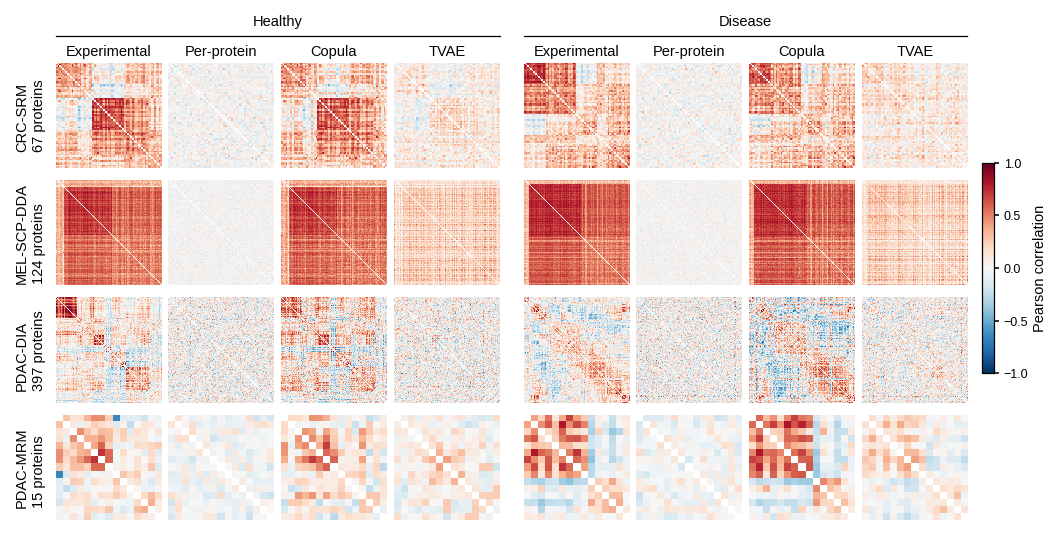

In [2]:
# Layout in inches; every heatmap is a square of side s
W = DOUBLE_COLUMN
left, right_cb, gap_block, gap = 0.30, 0.62, 0.16, 0.05
s = (W - left - right_cb - gap_block - 6 * gap) / 8
top_hdr, row_gap, bottom = 0.34, 0.08, 0.03
H = top_hdr + len(DATASETS) * s + (len(DATASETS) - 1) * row_gap + bottom
block_w = 4 * s + 3 * gap

fig = plt.figure(figsize=(W, H), layout="none")

# Group titles with a rule spanning each 4-panel block, simulator names over the columns
for b, title in enumerate(("Healthy", "Disease")):
    x0 = left + b * (block_w + gap_block)
    fig.text((x0 + block_w / 2) / W, (H - 0.02) / H, title, ha="center", va="top", fontsize=7)
    fig.add_artist(plt.Line2D([x0 / W, (x0 + block_w) / W], [(H - 0.16) / H] * 2,
                              color="black", linewidth=0.6))
    for c, name in enumerate(SIMULATOR_ORDER):
        fig.text((x0 + c * (s + gap) + s / 2) / W, (H - top_hdr + 0.03) / H, name,
                 ha="center", va="bottom", fontsize=7)

for r, (ds, (folder, groups)) in enumerate(DATASETS.items()):
    z = np.load(os.path.join(RESULTS_DIR, folder, "correlation_matrices.npz"))
    y_top = H - top_hdr - r * (s + row_gap)  # top edge of this row's heatmaps
    for b, group in enumerate(("healthy", "disease")):
        x0 = left + b * (block_w + gap_block)
        for c, name in enumerate(SIMULATOR_ORDER):
            ax = fig.add_axes([(x0 + c * (s + gap)) / W, (y_top - s) / H, s / W, s / H])
            corr = z[f"{group}__{name}"].copy()
            np.fill_diagonal(corr, np.nan)  # r = 1 diagonal carries no information
            im = corr_heatmap(ax, corr)
    # Row title: dataset name down the left margin
    fig.text(0.03 / W, (y_top - s / 2) / H, f"{ds}\n{len(z['healthy__proteins'])} proteins",
             rotation=90, ha="left", va="center", fontsize=7, linespacing=1.3)

cax = fig.add_axes([(W - right_cb + 0.10) / W, (H / 2 - s) / H, 0.08 / W, 2 * s / H])
cb = fig.colorbar(im, cax=cax, ticks=[-1, -0.5, 0, 0.5, 1])
cb.set_label("Pearson correlation", labelpad=2)
cb.outline.set_linewidth(0.6)

save_figure(fig, "correlation_heatmaps_v3", MAIN_FIG_DIR)  # v3: true PDAC-MRM labels, dataset order CRC, MEL, PDAC-DIA, PDAC-MRM
plt.show()

## Random Forest accuracy

Results section "Random Forest classifier trained on Copula-simulated data most often matched the accuracy of Random Forest classifier trained on experimental data". Accuracy on the held-out experimental validation set of a Random Forest trained on n biological replicates per group: of simulated data (one simulated dataset per iteration) or of the experimental training data (Experimental). One row per simulator, compared with the experimental reference in every panel. Line/markers: mean over 100 iterations; grey band and vertical bars: interquartile range. Source: `<dataset>/*_model_accuracy.csv`, written by the RF cells of each case-study notebook.

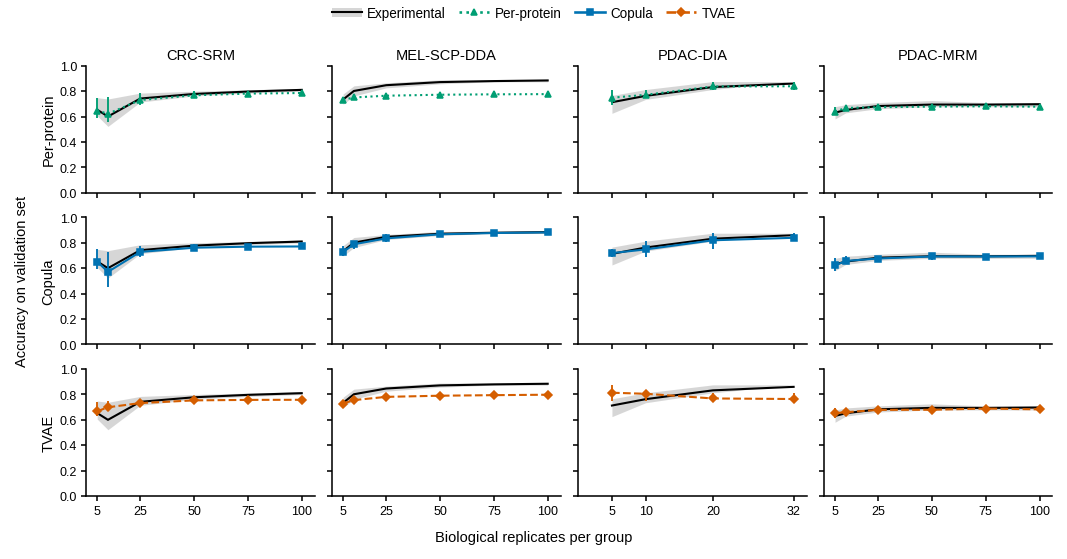

In [2]:
summaries = {ds: summarize_iterations(folder, "model_accuracy") for ds, (folder, _) in DATASETS.items()}
fig, axes = comparison_grid(summaries, "Accuracy on validation set", ylim=(0, 1))
save_figure(fig, "rf_accuracy_v3", MAIN_FIG_DIR)  # v3: RF re-run, true PDAC-MRM labels, dataset order CRC, MEL, PDAC-DIA, PDAC-MRM
plt.show()

## PCA variance explained

Results section "PCA trained on Copula-simulated data most often matched the variation explained by PCA trained on experimental data". Percentage of variance explained by the top five principal components, for n biological replicates per group sampled from the experimental training data (Experimental) or from one simulated dataset per iteration. One row per simulator, compared with the experimental reference in every panel. Line/markers: mean over 100 iterations; grey band and vertical bars: interquartile range. Source: `<dataset>/*_pca_var.csv`, written by the PCA cells of each case-study notebook.

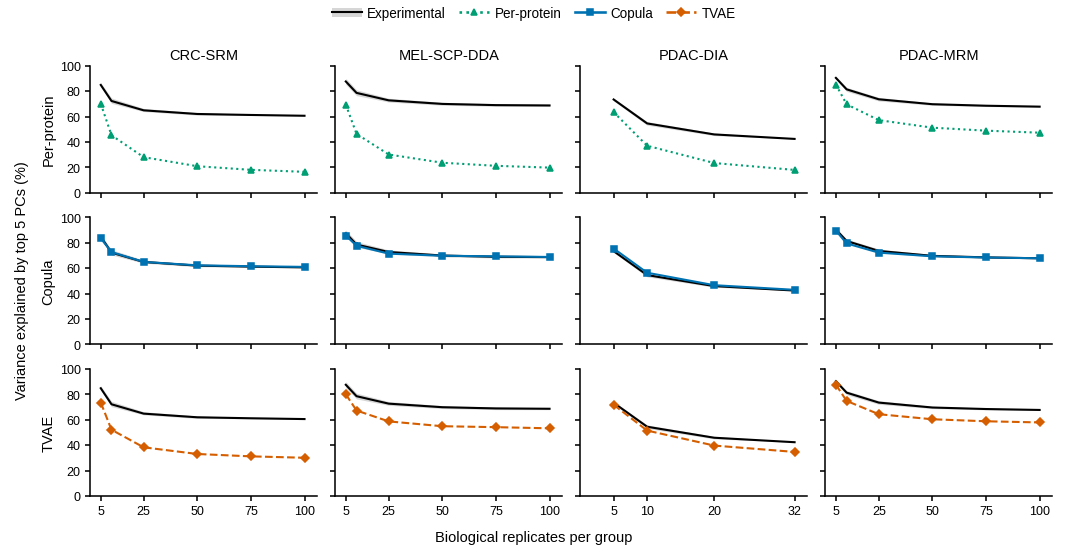

In [3]:
summaries = {ds: summarize_iterations(folder, "pca_var") for ds, (folder, _) in DATASETS.items()}
fig, axes = comparison_grid(summaries, "Variance explained by top 5 PCs (%)", ylim=(0, 100))
save_figure(fig, "pca_variance_v3", MAIN_FIG_DIR)  # v3: true PDAC-MRM labels, dataset order CRC, MEL, PDAC-DIA, PDAC-MRM
plt.show()

## t-test power

Results section "Copula-simulated data better match the power" (Devon, 2026-10-08; replaces the per-protein p-value curves). For each protein called significant (BH-adjusted) on the full experimental training data, power is the % of iterations in which a t-test on n biological replicates per group detects it: on subsamples of the experimental data (Experimental; validation set except PDAC-MRM, see notebooks) or on one simulated dataset per iteration. Line/markers: mean across those proteins; grey band and vertical bars: ± standard error across proteins. Source: `<dataset>/*_power_counts.csv` and `*_power_valid.csv`, written by the t-test cells of each case-study notebook.

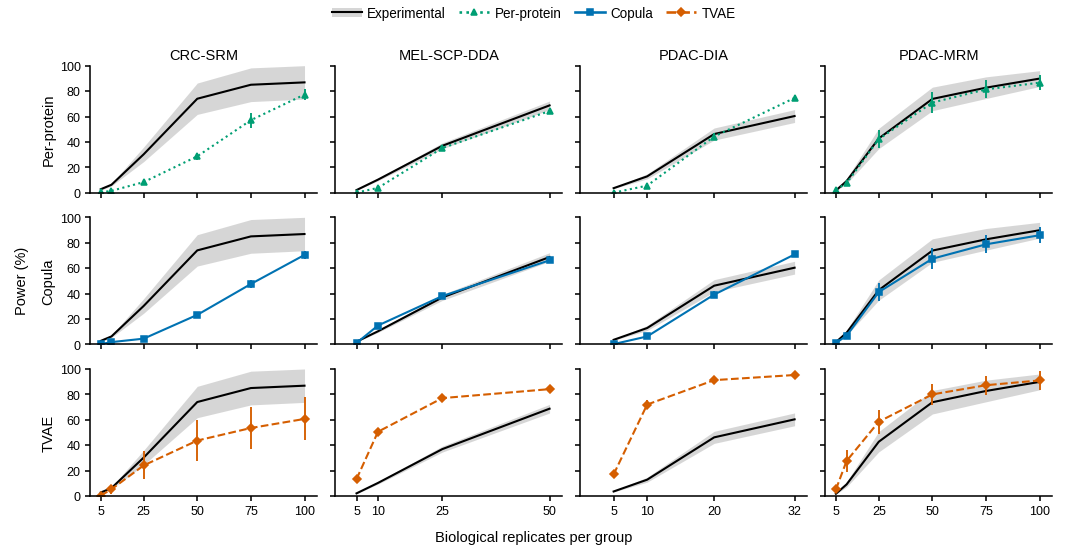

In [4]:
summaries = {ds: summarize_power(folder) for ds, (folder, _) in DATASETS.items()}
fig, axes = comparison_grid(summaries, "Power (%)", ylim=(0, 100))
save_figure(fig, "ttest_power_v3", MAIN_FIG_DIR)  # v3: true PDAC-MRM labels, dataset order CRC, MEL, PDAC-DIA, PDAC-MRM
plt.show()

## Sample-size recommendations table

Results table `tab:sample_size_recommendations` (Step 4 text merged into Step 3). Copula-based recommendations from the fine-grid runs saved by each case-study notebook (`<dataset>/copula_*_fine.csv`; 100 iterations per n). Rules (chosen 2026-10-08, documented in `plans/step4_table.md`):
- **Class prediction**: smallest n such that no grid point m with n < m ≤ n + 20 has mean accuracy more than 0.02 (absolute) above the mean at n.
- **Class discovery**: smallest n such that every grid point m with n < m ≤ n + 20 changes the mean % variance of the top 5 PCs by less than 1 percentage point.
- In both, n needs at least one grid point within +20; otherwise the result is reported as "≥ max n".
- **Class comparison**: smallest n where the mean power over the experimentally significant proteins reaches 80%; otherwise "> max n".

The numbers are written to `../data/results/sample_size_recommendations.csv` and pasted into `main.tex`.

In [3]:
def plateau_n(means, threshold, absolute_change):
    """Smallest n whose next +20 replicates change the mean by less than `threshold`."""
    n = means.index.to_numpy()
    for i, n0 in enumerate(n):
        window = means[(means.index > n0) & (means.index <= n0 + 20)]
        if window.empty:
            break
        change = (window - means[n0]).abs() if absolute_change else window - means[n0]
        if (change < threshold).all():
            return int(n0)
    return None


def fine(folder, kind):
    df = pd.read_csv(os.path.join(RESULTS_DIR, folder, f"copula_{kind}_fine.csv"), index_col=0)
    df.columns = df.columns.astype(int)
    return df


def fine_power(folder):
    counts = pd.read_csv(os.path.join(RESULTS_DIR, folder, "copula_power_counts_fine.csv"), index_col="Protein")
    counts.columns = counts.columns.astype(int)
    valid = pd.read_csv(os.path.join(RESULTS_DIR, folder, "copula_power_valid_fine.csv"),
                        index_col="n_samples")["n_valid"]
    return (100 * counts / valid.reindex(counts.columns).to_numpy()).mean()


rows = []
for ds, (folder, _) in DATASETS.items():
    acc = fine(folder, "model_accuracy").mean()
    pca = fine(folder, "pca_var").mean()
    power = fine_power(folder)
    n_acc = plateau_n(acc, 0.02, absolute_change=False)
    n_pca = plateau_n(pca, 1.0, absolute_change=True)
    reached = power[power >= 80]
    n_pow = int(reached.index[0]) if len(reached) else None
    max_n = int(acc.index.max())
    # Metric at the recommended n; if no n meets the rule, at the largest simulated n
    rows.append({
        "dataset": ds,
        "prediction_n": n_acc, "prediction_accuracy": acc[n_acc if n_acc else max_n],
        "discovery_n": n_pca, "discovery_pct_variance": pca[n_pca if n_pca else max_n],
        "comparison_n": n_pow, "comparison_power": power[n_pow if n_pow else max_n],
        "max_n": max_n,
    })
table = pd.DataFrame(rows)
table.to_csv(os.path.join(RESULTS_DIR, "sample_size_recommendations.csv"), index=False)


def fmt_n(n, max_n, above):
    return str(int(n)) if n is not None and not pd.isna(n) else (f"$\\geq${max_n}" if not above else f"$>${max_n}")


for r in table.itertuples():
    print(f"{{\\bf {r.dataset}}} & {fmt_n(r.prediction_n, r.max_n, False)} & {r.prediction_accuracy:.2f} & "
          f"{fmt_n(r.discovery_n, r.max_n, False)} & {r.discovery_pct_variance:.1f}\\% & "
          f"{fmt_n(r.comparison_n, r.max_n, True)} & {r.comparison_power:.0f}\\% \\\\")
table

{\bf CRC-SRM} & 40 & 0.75 & 50 & 62.4\% & $>$100 & 70\% \\
{\bf MEL-SCP-DDA} & 40 & 0.86 & 40 & 70.4\% & 90 & 82\% \\
{\bf PDAC-DIA} & 25 & 0.82 & $\geq$32 & 43.0\% & $>$32 & 71\% \\
{\bf PDAC-MRM} & 15 & 0.67 & 60 & 69.0\% & 80 & 82\% \\


,dataset,prediction_n,prediction_accuracy,discovery_n,discovery_pct_variance,comparison_n,comparison_power,max_n
0,CRC-SRM,40,0.745390,50.0,62.437688,NaN,70.428571,100
1,MEL-SCP-DDA,40,0.862222,40.0,70.363085,90.0,82.095652,100
2,PDAC-DIA,25,0.821338,NaN,42.984617,NaN,70.810345,32
3,PDAC-MRM,15,0.669355,60.0,68.990292,80.0,81.615385,100


## Limited training data (supplementary)

Supplementary section on limited training data. Copula (and Per-protein; TVAE for the full panel only) trained on random subsets of N cells of each MEL group, on the full 124-protein panel; S_corr of one simulated dataset (full group size) against the full-data correlation matrix; mean ± SD over 5 repeats (TVAE: one run per N). The smaller panels (15/30/60 proteins) are saved in the results file but not plotted (Devon, 2026-10-08). Source: `MEL/training_size_*`, written by `MEL_case_study.ipynb`.

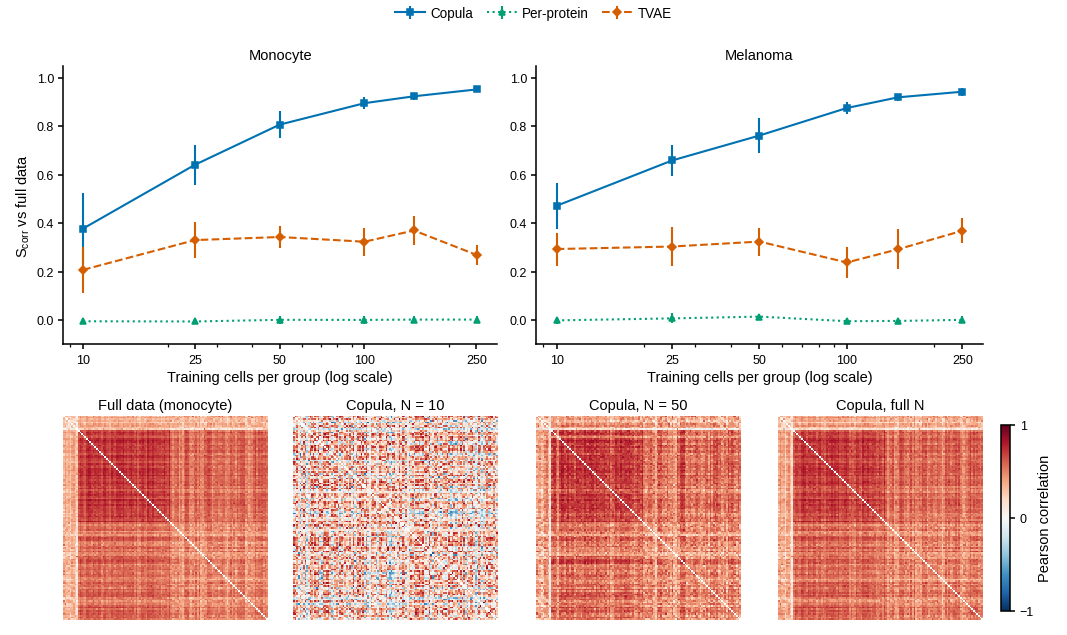

In [2]:
ts = pd.read_csv(os.path.join(RESULTS_DIR, "MEL", "training_size_scores.csv"))
extra = os.path.join(RESULTS_DIR, "MEL", "training_size_scores_tvae_extra.csv")  # TVAE repeats 2-5
if os.path.exists(extra):
    ts = pd.concat([ts, pd.read_csv(extra)], ignore_index=True)
zt = np.load(os.path.join(RESULTS_DIR, "MEL", "training_size_correlations.npz"))
P_FULL = ts.P.max()  # full MEL panel (124 proteins)
groups = [("healthy", "Monocyte"), ("disease", "Melanoma")]

fig = plt.figure(figsize=(DOUBLE_COLUMN, 4.2))
gs = fig.add_gridspec(2, 4, height_ratios=[1.2, 1])
for b, (group, title) in enumerate(groups):
    ax = fig.add_subplot(gs[0, 2 * b:2 * b + 2])
    g = ts[(ts.group == group) & (ts.P == P_FULL)]
    for sim in ("Copula", "Per-protein", "TVAE"):
        d = g[g.simulator == sim].groupby("N").s_corr.agg(["mean", "std", "count"]).reset_index()
        label = sim if d["count"].max() > 1 else f"{sim} (single run per N)"
        ax.errorbar(d.N, d["mean"], yerr=d["std"].fillna(0), markersize=3, linewidth=1.0, capsize=0,
                    label=label, **SIMULATOR_STYLES[sim])
    ax.set_xscale("log")
    ax.set_xticks([10, 25, 50, 100, 250], ["10", "25", "50", "100", "250"])
    ax.set_ylim(-0.1, 1.05)
    ax.set_title(title)
    ax.set_xlabel("Training cells per group (log scale)")
    if b == 0:
        ax.set_ylabel("S$_{corr}$ vs full data")
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=3)
examples = [("full_data", "Full data"), ("N10", "Copula, N = 10"), ("N50", "Copula, N = 50"), ("Nfull", "Copula, full N")]
for c, (key, title) in enumerate(examples):
    ax = fig.add_subplot(gs[1, c])
    corr = zt[f"healthy__{key}"].copy()
    np.fill_diagonal(corr, np.nan)
    im = corr_heatmap(ax, corr)
    ax.set_title(f"{title}" + (" (monocyte)" if c == 0 else ""))
cb = fig.colorbar(im, ax=fig.axes[-4:], shrink=0.8, ticks=[-1, 0, 1], pad=0.02)
cb.set_label("Pearson correlation")
save_figure(fig, "training_size_v2", SUPP_FIG_DIR)  # v1: TVAE single run per N
plt.show()

## Power curves: MRM vs DIA (semi-synthetic benchmark)

Plan 3.7 (`plans/acquisition_power.md`). Results from PDAC notebook > "Power curves: MRM vs DIA" (`data/results/PDAC_MRM/power_curves_*.csv`). Realized power of a Welch t-test + BH (FDR 0.05) in 500 experiments per setting: pseudo-groups drawn from the condition-centered data (semi-synthetic benchmark) or from Copula / Per-protein simulators fit once to the same data, with k proteins shifted by log2FC. Main text: log2FC = 1, pi1 = 0.20 (k = 3 of 15, 80 of 397); all settings in the supplementary. The figures read `PDAC_MRM/power_curves_figure_data.csv` (mean and SEM per setting, in the repository); set `PC_FROM_EXPERIMENTS = True` in the next cell to recompute it from `power_curves_experiments.csv` (on the lab server, see `data/results/SERVER_FILES.md`).

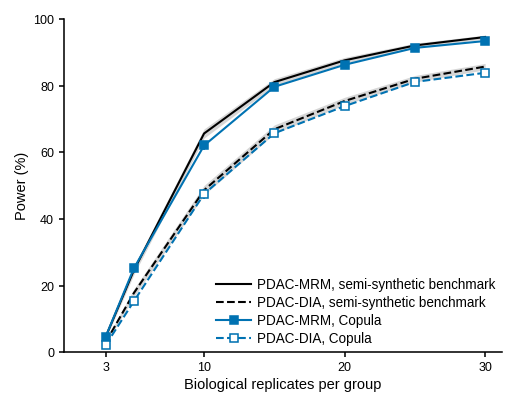

method                             Copula  Per-protein
protein_set log2fc pi1  n_changed                     
DIA-15      0.58   0.05 1             1.6          2.3
                   0.10 2             1.3          1.5
                   0.20 3             0.9          1.4
            1.00   0.05 1             2.9          3.9
                   0.10 2             2.0          1.7
                   0.20 3             1.4          1.7
DIA-397     0.58   0.05 20            1.0          1.2
                   0.10 40            0.9          1.8
                   0.20 80            0.9          1.8
            1.00   0.05 20            0.9          1.2
                   0.10 40            0.7          1.2
                   0.20 80            0.8          1.5
MRM-15      0.58   0.05 1             1.7          1.7
                   0.10 2             2.5          2.1
                   0.20 3             1.7          1.0
            1.00   0.05 1             1.9          1.6
          

In [2]:
PC_SETS = {"DIA-15": "PDAC-DIA, 15 proteins", "MRM-15": "PDAC-MRM, 15 proteins",
           "DIA-397": "PDAC-DIA, 397 proteins"}
PC_SIMS = ["Copula", "Per-protein"]
pc_keys = ["protein_set", "method", "log2fc", "pi1", "n_changed", "n_per_group"]
# Mean realized power (%) and its standard error over the 500 experiments of each setting. The repository holds
# exactly these plotted numbers (power_curves_figure_data.csv). With PC_FROM_EXPERIMENTS = True they are recomputed
# from the per-experiment file (power_curves_experiments.csv, 12.8 MB, on the lab server) and that file is rewritten.
PC_FROM_EXPERIMENTS = False
pc_figure_data = os.path.join(RESULTS_DIR, "PDAC_MRM", "power_curves_figure_data.csv")
if PC_FROM_EXPERIMENTS:
    pc_exp = pd.read_csv(os.path.join(RESULTS_DIR, "PDAC_MRM", "power_curves_experiments.csv"))
    pc_summary = (pc_exp.groupby(pc_keys).power.agg(["mean", "sem"]) * 100).reset_index()
    pc_summary.to_csv(pc_figure_data, index=False)
else:
    pc_summary = pd.read_csv(pc_figure_data, float_precision="round_trip")  # round_trip: the saved values exactly


def pc_curve(pset, method, log2fc, pi1):
    d = pc_summary[(pc_summary.protein_set == pset) & (pc_summary.method == method)
                   & np.isclose(pc_summary.log2fc, log2fc) & np.isclose(pc_summary.pi1, pi1)]
    d = d.sort_values("n_per_group")
    return d.n_per_group.to_numpy(), d["mean"].to_numpy(), d["sem"].to_numpy()


def pc_ticks(ax, n):
    ax.set_xticks([3, 10, 20, 30] if n.max() <= 30 else [3, 25, 50, 75, 100])
    ax.set_xlim(0, n.max() * 1.06)


from MSquantSim.plotting import SINGLE_COLUMN


def power_curve_figure(log2fc, pi1, n_max=30):
    """
    One panel: semi-synthetic benchmark (real data, black lines) and Copula (blue squares) power curves for
    PDAC-MRM (solid) and PDAC-DIA (dashed, open markers) on the 15 shared proteins, N <= n_max.
    """
    copula = SIMULATOR_STYLES["Copula"]["color"]
    acquisitions = {"MRM-15": ("PDAC-MRM", "-", copula), "DIA-15": ("PDAC-DIA", "--", "white")}
    fig, ax = plt.subplots(figsize=(SINGLE_COLUMN, 2.6))
    handles, labels = [], []
    for pset, (name, linestyle, face) in acquisitions.items():
        n, m, s = pc_curve(pset, "Semi-synthetic benchmark", log2fc, pi1)
        keep = n <= n_max
        ax.fill_between(n[keep], (m - s)[keep], (m + s)[keep], color="0.55", alpha=0.35, linewidth=0)
        line, = ax.plot(n[keep], m[keep], color="black", linestyle=linestyle, linewidth=1.0, marker="")
        handles.append(line); labels.append(f"{name}, semi-synthetic benchmark")
    for pset, (name, linestyle, face) in acquisitions.items():
        n, m, s = pc_curve(pset, "Copula", log2fc, pi1)
        keep = n <= n_max
        ax.vlines(n[keep], (m - s)[keep], (m + s)[keep], color=copula, linewidth=0.8)
        line, = ax.plot(n[keep], m[keep], color=copula, linestyle=linestyle, linewidth=1.0, marker="s",
                        markersize=3.5, markerfacecolor=face, markeredgecolor=copula)
        handles.append(line); labels.append(f"{name}, Copula")
    ax.set_xticks([3, 10, 20, 30])
    ax.set_xlim(0, n_max * 1.04)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Biological replicates per group")
    ax.set_ylabel("Power (%)")
    ax.legend(handles, labels, loc="lower right", handlelength=2.6)
    return fig


fig = power_curve_figure(1.0, 0.20)
save_figure(fig, "acquisition_power_v5", MAIN_FIG_DIR)  # v5: one panel, semi-synthetic benchmark + Copula, MRM vs DIA (15 proteins)
plt.show()

# Claim (a): mean |simulator - semi-synthetic benchmark| of the mean power (percentage points) over N, per setting
pc_ref = pc_summary[pc_summary.method == "Semi-synthetic benchmark"].drop(columns=["method", "sem"])
pc_gap = (pc_summary[pc_summary.method != "Semi-synthetic benchmark"]
          .merge(pc_ref, on=[k for k in pc_keys if k != "method"], suffixes=("", "_benchmark"))
          .assign(gap=lambda d: (d["mean"] - d["mean_benchmark"]).abs())
          .groupby(["protein_set", "log2fc", "pi1", "n_changed", "method"])["gap"].mean()
          .unstack("method").round(1))
print(pc_gap.to_string())
print("settings where Copula is closer:", int((pc_gap["Copula"] < pc_gap["Per-protein"]).sum()),
      "of", len(pc_gap), "| max SEM (points):", round(pc_summary["sem"].max(), 2))

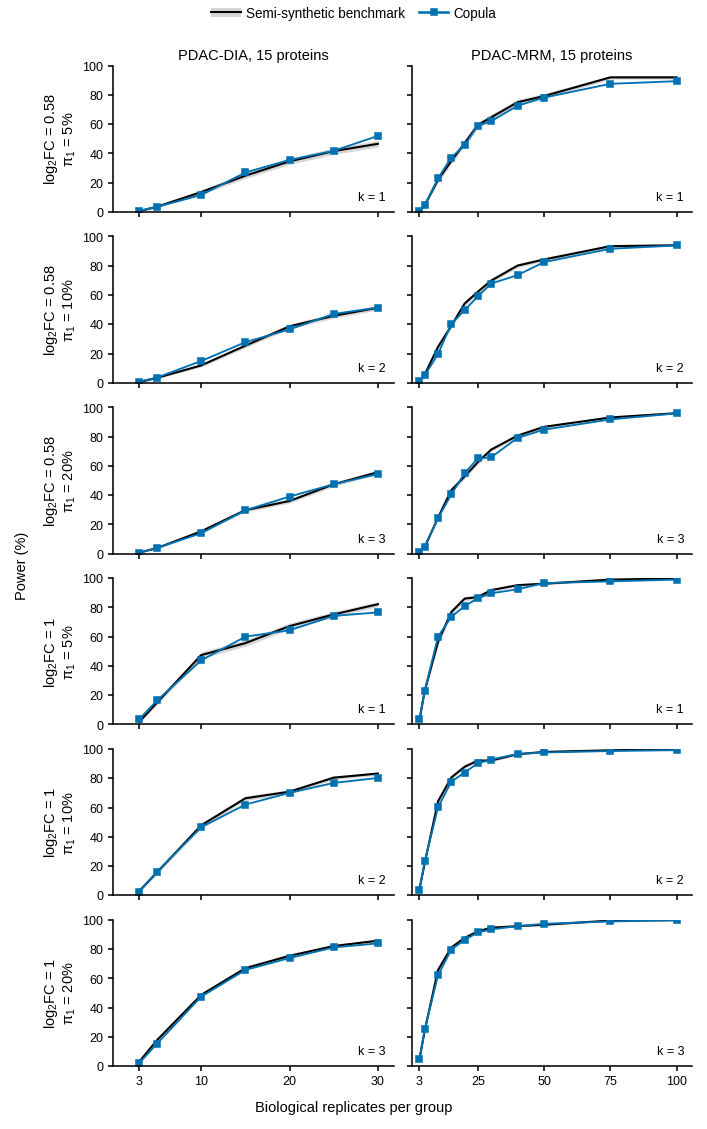

In [3]:
# All settings (supplementary): rows log2FC x pi1, columns PDAC-DIA and PDAC-MRM on the 15 shared proteins;
# semi-synthetic benchmark (black line, band = mean +- SEM) with the Copula mean overlaid (its SEM, <= 2.2 points,
# is smaller than the markers)
SETTINGS_SETS = {k: v for k, v in PC_SETS.items() if k != "DIA-397"}
fcs, pis = sorted(pc_summary.log2fc.unique()), sorted(pc_summary.pi1.unique())
fig, axes = plt.subplots(len(fcs) * len(pis), len(SETTINGS_SETS), sharey=True, sharex="col",
                         figsize=(4.6, 7.4))
for c, (pset, title) in enumerate(SETTINGS_SETS.items()):
    for i, (fc, pi1) in enumerate([(f, q) for f in fcs for q in pis]):
        ax = axes[i, c]
        n, m_ref, s_ref = pc_curve(pset, "Semi-synthetic benchmark", fc, pi1)
        ax.fill_between(n, m_ref - s_ref, m_ref + s_ref, color="0.55", alpha=0.35, linewidth=0)
        ax.plot(n, m_ref, color="black", linewidth=1.0, marker="")
        _, m, _ = pc_curve(pset, "Copula", fc, pi1)
        ax.plot(n, m, markersize=2.5, linewidth=0.9, **SIMULATOR_STYLES["Copula"])
        pc_ticks(ax, n)
        k = int(pc_summary[(pc_summary.protein_set == pset) & np.isclose(pc_summary.pi1, pi1)].n_changed.iloc[0])
        ax.text(0.97, 0.06, f"k = {k}", transform=ax.transAxes, ha="right", va="bottom", fontsize=6)
        if i == 0:
            ax.set_title(title)
        if c == 0:
            ax.set_ylabel(f"log$_2$FC = {fc:g}\n$\\pi_1$ = {pi1:.0%}")
axes[0, 0].set_ylim(0, 100)
fig.supylabel("Power (%)")
fig.supxlabel("Biological replicates per group")
handles = [(Patch(color="0.55", alpha=0.35, linewidth=0), Line2D([], [], color="black", linewidth=1.0)),
           Line2D([], [], markersize=3, **SIMULATOR_STYLES["Copula"])]
fig.legend(handles, ["Semi-synthetic benchmark", "Copula"], loc="outside upper center", ncols=2)
save_figure(fig, "acquisition_power_settings_v6", SUPP_FIG_DIR)  # v6: Copula only, PDAC-DIA and PDAC-MRM (15 proteins)
plt.show()


## Paper figure candidates: P(TPR ≥ 0.8) and P(FDP ≤ 0.05) side by side (K = 5%)

Devon, 2026-10-20. Clustered placement, K = 5% of the proteins DE (MEL-SCP-DDA 6, PDAC-DIA 20). Left column: P(TPR ≥ 0.8), the chance that one experiment detects at least 80% of the DE proteins; the dotted line is the standard calculator's n for 80% mean power. Right column: P(FDP ≤ 0.05), the chance that at most 5% of its discoveries are false (FDP = 0 when nothing is discovered). Rows: log2FC = 0.58 and 1. Ground truth = semi-synthetic benchmark on the real null-ified data; Per-protein and Copula on the same truth assignments; 500 replicates per point; Welch t-test + BH at FDR 0.05. PDAC-DIA: the ground truth stops at n = 39 and reuses most samples above n = 20 (shaded). Saved to `figures/results/sample_size/`. Self-contained; needs cell 2.

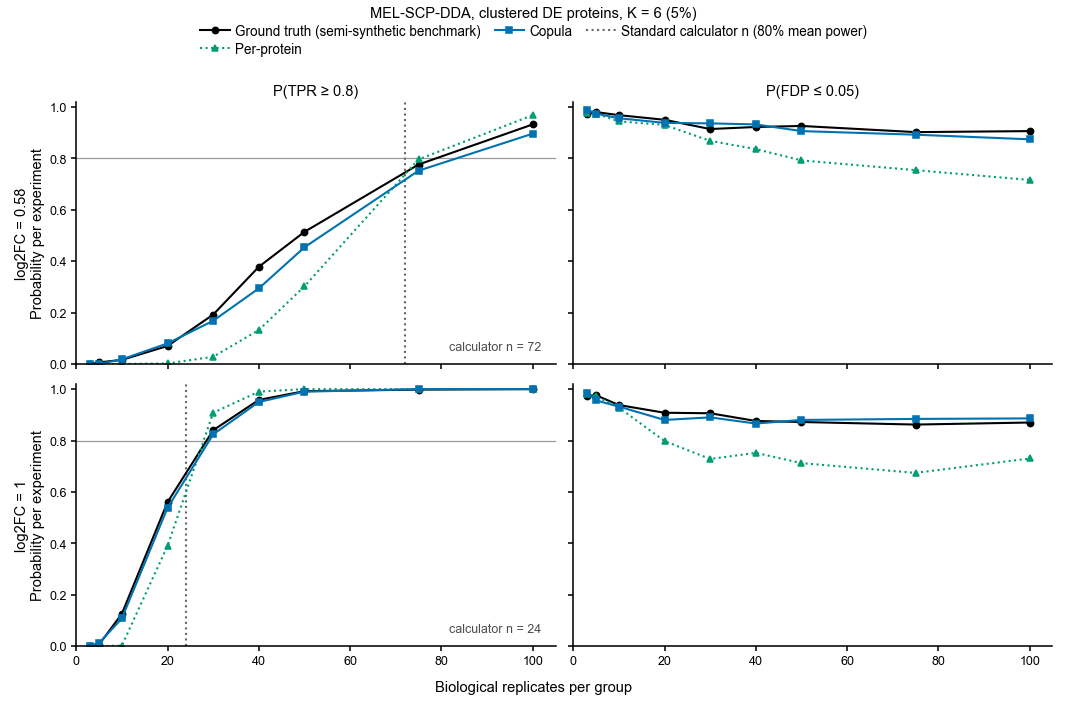

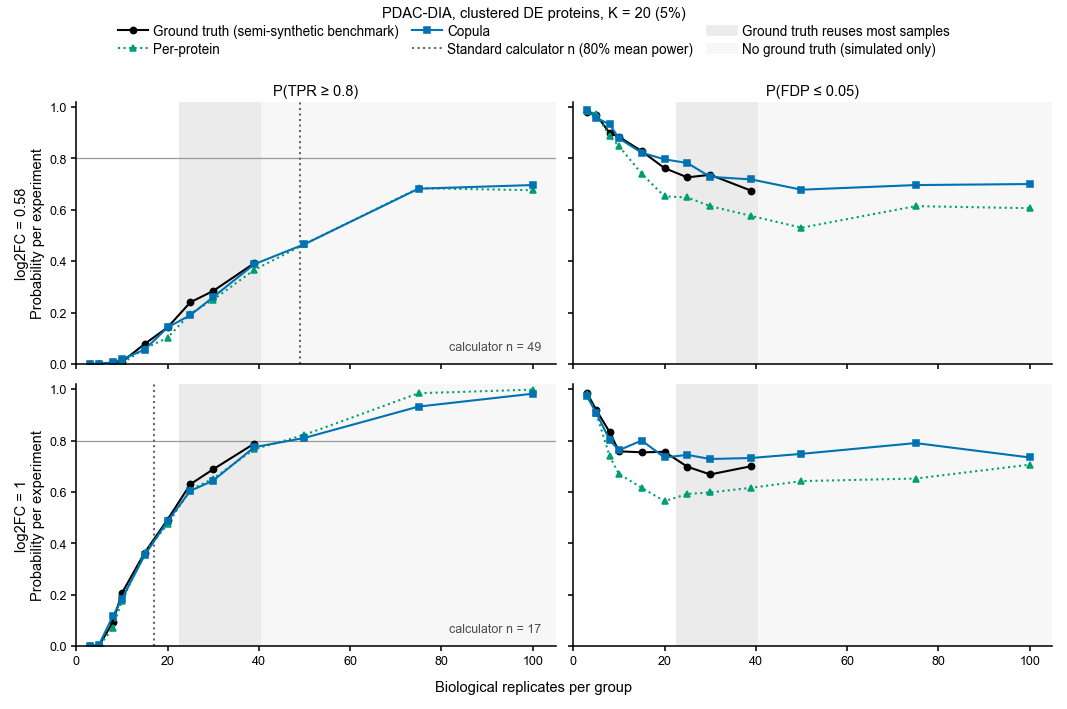

In [2]:
# Paper figure candidates: P(TPR >= 0.8) (left) and P(FDP <= 0.05) (right), clustered placement, K = 5%
TF_STYLES = {
    "ground_truth": dict(SIMULATOR_STYLES["Experimental"], label="Ground truth (semi-synthetic benchmark)"),
    "perprotein_sim": dict(SIMULATOR_STYLES["Per-protein"], label="Per-protein"),
    "copula": dict(SIMULATOR_STYLES["Copula"], label="Copula"),
}
TF_DATASETS = {
    "MEL": dict(label="MEL-SCP-DDA", n_proteins=124, K=6, reuse_n=None),
    "PDAC_DIA": dict(label="PDAC-DIA", n_proteins=397, K=20, reuse_n=20),
}
TF_METRICS = [("p_tpr", "P(TPR ≥ 0.8)"), ("p_fdp", "P(FDP ≤ 0.05)")]
# Section 4.2 figures live in their own subfolder (Devon, 2026-10-21)
SS_FIG_DIR = os.path.join(FIG_DIR, "sample_size")


def tf_curves(dataset, K, placement="clustered"):
    path = lambda f: os.path.join(RESULTS_DIR, dataset, f)
    gt = pd.read_csv(path("placement_replicates.csv"))
    gt = gt[gt.correlation == "correlated"].assign(method="ground_truth")
    reps = pd.concat([gt, pd.read_csv(path("placement_methods_replicates.csv")),
                      pd.read_csv(path("placement_perprotein_replicates.csv"))], ignore_index=True)
    reps = reps[(reps.placement == placement) & (reps.K == K) & reps.method.isin(TF_STYLES)]
    curves = (reps.assign(tpr_ok=reps.tpr >= 0.8, fdp_ok=reps.fdp <= 0.05)
              .groupby(["method", "log2fc", "n_per_group"])
              .agg(p_tpr=("tpr_ok", "mean"), p_fdp=("fdp_ok", "mean"), size=("tpr_ok", "size")).reset_index())
    assert (curves["size"] == 500).all(), "expected 500 replicates per point"
    calc = pd.read_csv(path("placement_calculator.csv"))
    return curves, calc[calc.K == K]


def tf_figure(dataset, name):
    cfg = TF_DATASETS[dataset]
    curves, calc = tf_curves(dataset, cfg["K"])
    gt_max = curves[curves.method == "ground_truth"].n_per_group.max()
    n_max = curves.n_per_group.max()
    fcs = [0.58, 1.0]
    fig, axes = plt.subplots(len(fcs), len(TF_METRICS), figsize=(DOUBLE_COLUMN, 4.6), sharex=True, sharey=True)
    for r, fc in enumerate(fcs):
        for c, (metric, title) in enumerate(TF_METRICS):
            ax = axes[r, c]
            if cfg["reuse_n"] is not None:
                ax.axvspan(cfg["reuse_n"] + 2.5, gt_max + 1.5, color="0.92", linewidth=0, zorder=0)
            if gt_max < n_max:
                ax.axvspan(gt_max + 1.5, n_max * 1.05, color="0.97", linewidth=0, zorder=0)
            if metric == "p_tpr":
                ax.axhline(0.8, color="0.6", linewidth=0.6)
                n_calc = calc[np.isclose(calc.log2fc, fc)].n_calculator.iloc[0]
                ax.axvline(n_calc, color="0.4", linestyle=":", linewidth=1.0)
                ax.text(0.97, 0.04, f"calculator n = {n_calc}", transform=ax.transAxes, ha="right", va="bottom",
                        fontsize=6, color="0.3")
            for method, style in TF_STYLES.items():
                d = curves[(curves.method == method) & np.isclose(curves.log2fc, fc)].sort_values("n_per_group")
                ax.plot(d.n_per_group, d[metric], markersize=3, linewidth=1.0, **style)
            ax.set_ylim(0, 1.02)
            ax.set_xlim(0, n_max * 1.05)
            if r == 0:
                ax.set_title(title)
            if c == 0:
                ax.set_ylabel(f"log2FC = {fc:g}\nProbability per experiment")
    fig.supxlabel("Biological replicates per group")
    handles = [Line2D([], [], markersize=3, linewidth=1.0, **s) for s in TF_STYLES.values()]
    handles.append(Line2D([], [], color="0.4", linestyle=":", linewidth=1.0, label="Standard calculator n (80% mean power)"))
    if cfg["reuse_n"] is not None:
        handles.append(Patch(color="0.92", label="Ground truth reuses most samples"))
    if gt_max < n_max:
        handles.append(Patch(color="0.97", label="No ground truth (simulated only)"))
    fig.legend(handles=handles, loc="outside upper center", ncols=3,
               title=f"{cfg['label']}, clustered DE proteins, K = {cfg['K']} ({cfg['K'] / cfg['n_proteins']:.0%})")
    os.makedirs(SS_FIG_DIR, exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(SS_FIG_DIR, f"{name}.{ext}"))
    plt.show()


tf_figure("MEL", "sample_size_tpr_fdp_mel")
tf_figure("PDAC_DIA", "sample_size_tpr_fdp_pdac")


# Reserve (not used in the paper)

Older and superseded analyses, kept for reference. Nothing in the paper depends on the cells below. They were moved here unchanged on 2026-10-21 (`plans/notebook_reorder.md`); running the notebook from the top gives them the same inputs as before.

## Sample size: correlation-aware (MEL pilot)

Replaces the "individual proteins" Step 4 figure (plan 4.2). MEL-SCP-DDA, all 628 cells, condition effect removed (semi-synthetic benchmark). 500 simulated experiments per method, design setting and N; known log2 fold change added to ceil(π₁ · 124) proteins; Welch t-test + BH at FDR 0.05. Methods: semi-synthetic benchmark (real data, reference), Copula (full correlation), Copula with the correlation set to the identity (same marginals), and the independence-based calculator (MSstats-style, median variance). Source: `MEL/sample_size_*.csv`, written by the pilot section of `MEL_case_study.ipynb`.

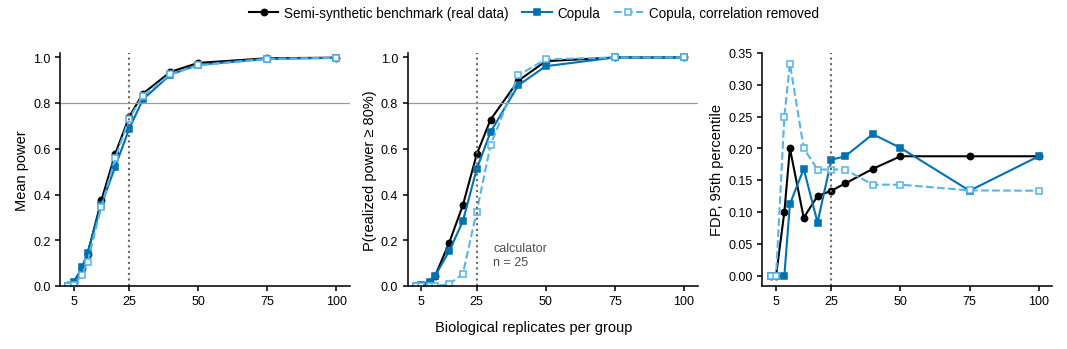

In [2]:
SS_STYLES = {
    "benchmark": dict(color="#000000", marker="o", linestyle="-", label="Semi-synthetic benchmark (real data)"),
    "copula": dict(color=SIMULATOR_STYLES["Copula"]["color"], marker="s", linestyle="-", label="Copula"),
    "copula_independent": dict(color="#56B4E9", marker="s", markerfacecolor="white", linestyle="--",
                               label="Copula, correlation removed"),
}
ss_summary = pd.read_csv(os.path.join(RESULTS_DIR, "MEL", "sample_size_summary.csv"))
ss_calc = pd.read_csv(os.path.join(RESULTS_DIR, "MEL", "sample_size_calculator.csv"))


def ss_axes(ax, setting, metric, ylabel):
    fc, pi1 = setting
    sub = ss_summary[(ss_summary.log2fc == fc) & (ss_summary.pi1 == pi1)]
    for method, style in SS_STYLES.items():
        d = sub[sub.method == method].sort_values("n_per_group")
        ax.plot(d.n_per_group, d[metric], markersize=3, linewidth=1.0, **style)
    n_calc = ss_calc[(ss_calc.log2fc == fc) & (ss_calc.pi1 == pi1)].n_calculator.iloc[0]
    ax.axvline(n_calc, color="0.4", linestyle=":", linewidth=1.0)
    ax.set_xticks([5, 25, 50, 75, 100])
    ax.set_xlim(0, 105)
    ax.set_ylabel(ylabel)
    return n_calc


main_setting = (1.0, 0.1)
fig, axes = plt.subplots(1, 3, figsize=(DOUBLE_COLUMN, 2.2))
for ax, (metric, ylabel) in zip(axes, [("mean_power", "Mean power"),
                                       ("p_power_ge_target", "P(realized power ≥ 80%)"),
                                       ("fdp_q95", "FDP, 95th percentile")]):
    n_calc = ss_axes(ax, main_setting, metric, ylabel)
    if metric != "fdp_q95":
        ax.axhline(0.8, color="0.6", linewidth=0.6)
        ax.set_ylim(0, 1.02)
axes[1].annotate(f"calculator\nn = {n_calc}", xy=(n_calc, 0.08), xytext=(n_calc + 6, 0.08),
                 fontsize=6, color="0.3", va="bottom")
fig.supxlabel("Biological replicates per group")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=3)
save_figure(fig, "sample_size_pilot_v2")
plt.show()

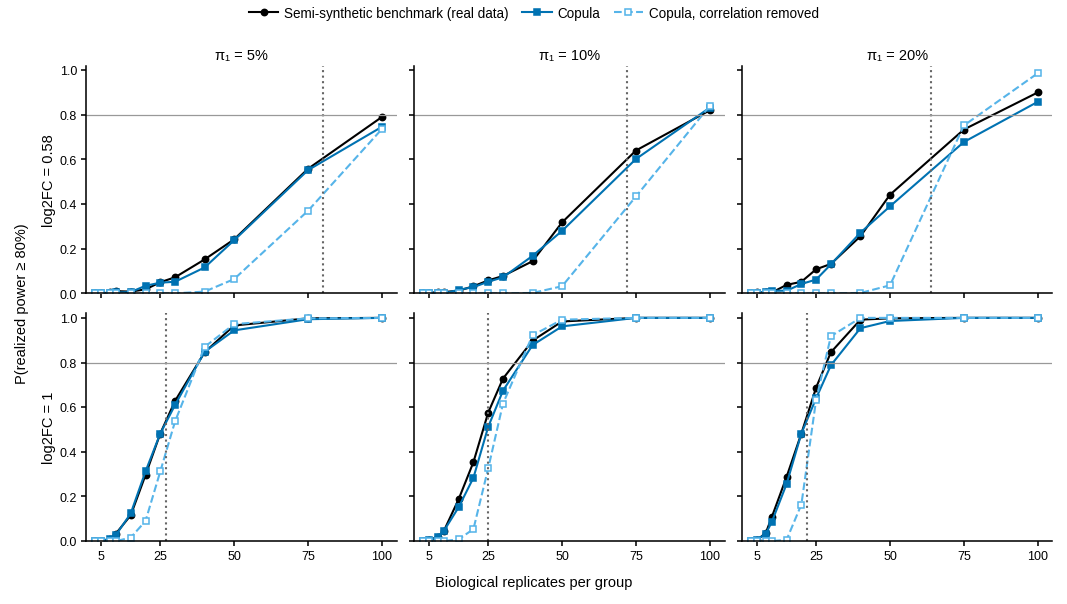

In [3]:
# Full design grid (supplementary): P(realized power >= 80%) for every log2FC x pi1 setting
fcs, pis = sorted(ss_summary.log2fc.unique()), sorted(ss_summary.pi1.unique())
fig, axes = plt.subplots(len(fcs), len(pis), figsize=(DOUBLE_COLUMN, 3.9), sharex=True, sharey=True)
for r, fc in enumerate(fcs):
    for c, pi1 in enumerate(pis):
        ax = axes[r, c]
        ss_axes(ax, (fc, pi1), "p_power_ge_target", f"log2FC = {fc:g}" if c == 0 else "")
        ax.axhline(0.8, color="0.6", linewidth=0.6)
        ax.set_ylim(0, 1.02)
        if r == 0:
            ax.set_title(f"π₁ = {pi1:.0%}")
fig.supylabel("P(realized power ≥ 80%)")
fig.supxlabel("Biological replicates per group")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=3)
save_figure(fig, "sample_size_grid_v2")
plt.show()

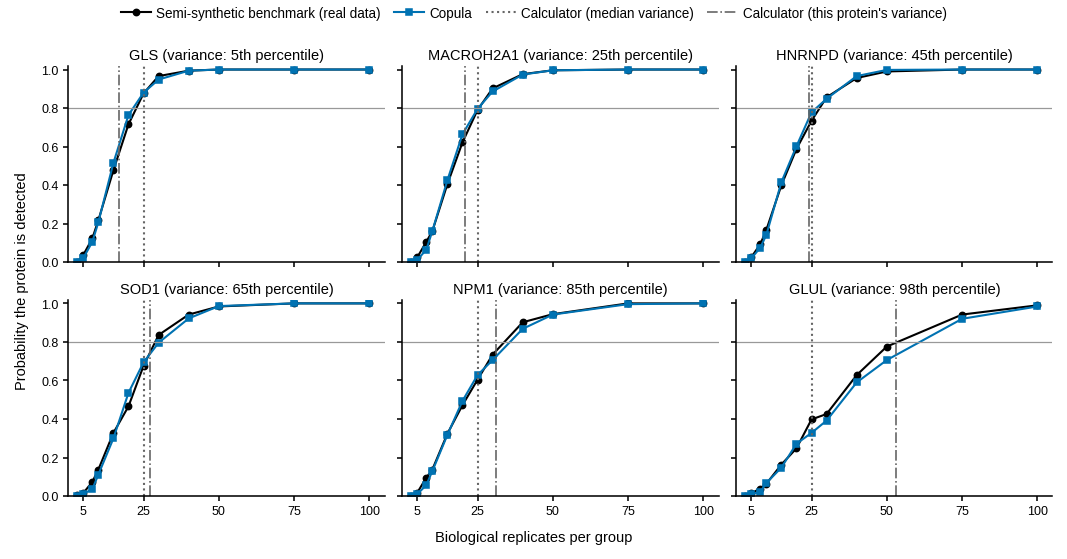

In [4]:
# Individual proteins: calculator n vs the n each protein actually needs (semi-synthetic benchmark) and Copula's estimate
det = pd.read_csv(os.path.join(RESULTS_DIR, "MEL", "sample_size_protein_detection.csv"))
pcalc = pd.read_csv(os.path.join(RESULTS_DIR, "MEL", "sample_size_protein_calculator.csv"))
pcalc = pcalc.sort_values("variance_percentile")
fig, axes = plt.subplots(2, 3, figsize=(DOUBLE_COLUMN, 3.6), sharex=True, sharey=True)
for ax, row in zip(axes.flat, pcalc.itertuples()):
    for method in ("benchmark", "copula"):
        d = det[(det.protein == row.protein) & (det.method == method)].sort_values("n_per_group")
        ax.plot(d.n_per_group, d.detection_rate, markersize=3, linewidth=1.0, **SS_STYLES[method])
    ax.axhline(0.8, color="0.6", linewidth=0.6)
    ax.axvline(row.n_representative, color="0.4", linestyle=":", linewidth=1.0)
    ax.axvline(row.n_protein_calculator, color="0.4", linestyle="-.", linewidth=0.8)
    ax.set_title(f"{row.protein} (variance: {row.variance_percentile:.0f}th percentile)")
    ax.set_xticks([5, 25, 50, 75, 100])
    ax.set_xlim(0, 105)
    ax.set_ylim(0, 1.02)
fig.supylabel("Probability the protein is detected")
fig.supxlabel("Biological replicates per group")
handles, labels = axes[0, 0].get_legend_handles_labels()
handles += [Line2D([], [], color="0.4", linestyle=":", linewidth=1.0),
            Line2D([], [], color="0.4", linestyle="-.", linewidth=0.8)]
labels += ["Calculator (median variance)", "Calculator (this protein's variance)"]
fig.legend(handles, labels, loc="outside upper center", ncols=4)
save_figure(fig, "sample_size_proteins_v2")
plt.show()

## Missing values: KNN imputation before simulation (supplementary)

Supplementary section "Effect of KNN imputation on simulator training data". MEL-SCP-DDA training data per group; missing values introduced with the fitted MNAR detection curve at increasing overall rates, KNN-imputed (k = 5), then used to train each simulator. Heatmaps: Pearson correlations, proteins ordered by clustering the complete data of each group. Source: `MEL/missingness_*`, written by `MEL_case_study.ipynb`.

> **Not used in the paper (Devon, 2026-10-08):** the missing-values section was dropped from the manuscript and supplementary. The code and results are kept for reference only.

/tmp/ipykernel_290989/3215374105.py:30: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"))


/home/devon/anaconda3/envs/msquantsim/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


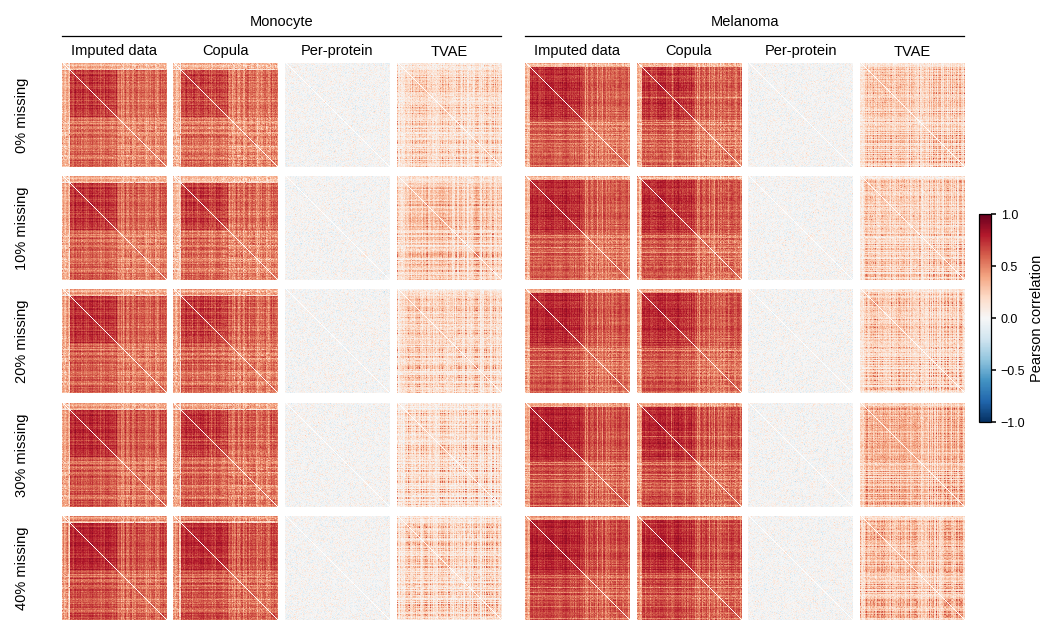

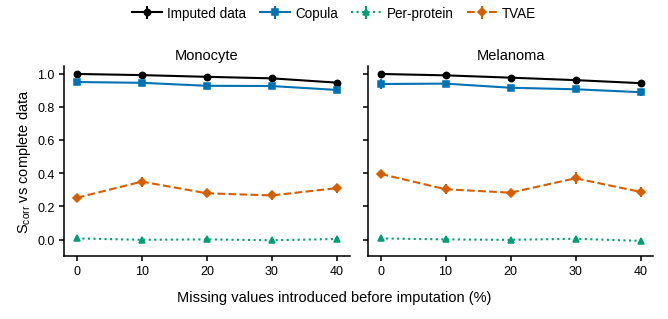

In [5]:
z = np.load(os.path.join(RESULTS_DIR, "MEL", "missingness_correlations.npz"))
levels = sorted({k.split("__")[1] for k in z.files if "__r" in k}, key=lambda s: int(s[1:]))
sources = [("Imputed", "Imputed data"), ("Copula", "Copula"), ("Per-protein", "Per-protein"), ("TVAE", "TVAE")]
groups = [("healthy", "Monocyte"), ("disease", "Melanoma")]

W = DOUBLE_COLUMN
left, right_cb, gap_block, gap = 0.36, 0.62, 0.16, 0.05
s = (W - left - right_cb - gap_block - 6 * gap) / 8
top_hdr, row_gap, bottom = 0.34, 0.06, 0.03
H = top_hdr + len(levels) * s + (len(levels) - 1) * row_gap + bottom
block_w = 4 * s + 3 * gap
fig = plt.figure(figsize=(W, H), layout="none")
for b, (_, title) in enumerate(groups):
    x0 = left + b * (block_w + gap_block)
    fig.text((x0 + block_w / 2) / W, (H - 0.02) / H, title, ha="center", va="top", fontsize=7)
    fig.add_artist(plt.Line2D([x0 / W, (x0 + block_w) / W], [(H - 0.16) / H] * 2, color="black", linewidth=0.6))
    for c, (_, name) in enumerate(sources):
        fig.text((x0 + c * (s + gap) + s / 2) / W, (H - top_hdr + 0.03) / H, name, ha="center", va="bottom", fontsize=7)
for r, level in enumerate(levels):
    y_top = H - top_hdr - r * (s + row_gap)
    for b, (group, _) in enumerate(groups):
        x0 = left + b * (block_w + gap_block)
        for c, (src, _) in enumerate(sources):
            ax = fig.add_axes([(x0 + c * (s + gap)) / W, (y_top - s) / H, s / W, s / H])
            corr = z[f"{group}__{level}__{src}"].copy()
            np.fill_diagonal(corr, np.nan)
            im = corr_heatmap(ax, corr)
    fig.text(0.05 / W, (y_top - s / 2) / H, f"{int(level[1:])}% missing", rotation=90,
             ha="left", va="center", fontsize=7)
cax = fig.add_axes([(W - right_cb + 0.10) / W, (H / 2 - s) / H, 0.08 / W, 2 * s / H])
cb = fig.colorbar(im, cax=cax, ticks=[-1, -0.5, 0, 0.5, 1])
cb.set_label("Pearson correlation", labelpad=2)
cb.outline.set_linewidth(0.6)
save_figure(fig, "missingness_heatmaps")
plt.show()

# S_corr against the complete data, by missing-value rate
scores = pd.read_csv(os.path.join(RESULTS_DIR, "MEL", "missingness_scores.csv"))
fig, axes = plt.subplots(1, 2, figsize=(DOUBLE_COLUMN * 0.62, 2.0), sharey=True)
src_styles = {"Imputed": dict(color="black", marker="o", linestyle="-"),
              "Copula": SIMULATOR_STYLES["Copula"], "Per-protein": SIMULATOR_STYLES["Per-protein"],
              "TVAE": SIMULATOR_STYLES["TVAE"]}
labels_src = {"Imputed": "Imputed data", "Copula": "Copula", "Per-protein": "Per-protein", "TVAE": "TVAE"}
for ax, (group, title) in zip(axes, groups):
    g = scores[scores.group == group]
    for src, style in src_styles.items():
        d = g[g.source == src].groupby("target_rate").s_corr.agg(["mean", "std"]).reset_index()
        ax.errorbar(100 * d.target_rate, d["mean"], yerr=d["std"].fillna(0), markersize=3, linewidth=1.0,
                    capsize=0, label=labels_src[src], **style)
    ax.set_title(title)
    ax.set_xticks([0, 10, 20, 30, 40])
    ax.set_ylim(-0.1, 1.05)
axes[0].set_ylabel("S$_{corr}$ vs complete data")
fig.supxlabel("Missing values introduced before imputation (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=4)
save_figure(fig, "missingness_scores")
plt.show()

## Sample size: seed-protein design (PDAC-DIA pilot)

Plan 4.2 redesign (`plans/sample_size.md`, "Redesign: PDAC-DIA seed proteins"). Source: `PDAC_DIA/sample_size_seed_*.csv`, written by `PDAC_case_study.ipynb` > "Sample size: seed-protein design (4.2)". PDAC-DIA, 79 serum samples (sample `1E446_Normal` excluded for 4.2: 77.5% missing), 397 proteins, condition effect removed. Each run draws 5 seed proteins; the changed set is the seeds plus their correlated partners (rule A: the 3 most correlated proteins per seed, 20 changed; rule B: every protein with r ≥ 0.5, at most 15 per seed). The semi-synthetic benchmark (real data) and Copula use the seed sets; Copula with the correlation removed uses a fixed 5% of proteins changed at random (20 of 397; Devon, 2026-10-16), the independence planner's assumption, and so does the calculator (π₁ = 5%). 500 runs per rule, method, log2FC and N; Welch t-test + BH at FDR 0.05. Above N = 20 the benchmark experiments reuse most of the 79 samples (shaded). Needs cell 2.

In [2]:
# Seed-protein pilot figures: rows = changed-set rule; panels = mean power, P(realized power >= 80%),
# mean FDP and detected true positives. Benchmark and Copula: seed sets; correlation removed: 5% random.
# Definitions only; each dataset's figures are made in their own cell below.
SEED_STYLES = {
    "benchmark": dict(color="#000000", marker="o", linestyle="-", label="Semi-synthetic benchmark (real data), seed sets"),
    "copula": dict(color=SIMULATOR_STYLES["Copula"]["color"], marker="s", linestyle="-", label="Copula, seed sets"),
    "copula_independent": dict(color="#56B4E9", marker="s", markerfacecolor="white", linestyle="--",
                               label="Copula, correlation removed, 5% random"),
}
SEED_DATASETS = {
    "PDAC_DIA": dict(rules={"A": "Rule A: 5 seeds + their 3 most correlated proteins each (20 changed)",
                            "B": "Rule B: 5 seeds + proteins with r ≥ 0.5, at most 15 each (median 30 changed)"},
                     reliable_n=20,  # benchmark pool of 79 samples: above N = 20 each run reuses most of them
                     random_k=20, label="PDAC-DIA"),
    "MEL": dict(rules={"A": "Rule A: 2 seeds + their 2 most correlated proteins each (6 changed)",
                       "B": "Rule B: 2 seeds + proteins with r ≥ 0.5, at most 15 each (median 24 changed)"},
                reliable_n=None,  # 628 cells: no sample reuse up to N = 100
                random_k=6, label="MEL-SCP-DDA"),
}
SEED_PANELS = [("mean_power", "Mean power"),
               ("p_power_ge_target", "P(realized power ≥ 80%)"),
               ("fdp_mean", "Mean FDP"),
               ("mean_tp", "Detected true positives")]


def seed_figure(dataset, log2fc, name):
    cfg = SEED_DATASETS[dataset]
    summary = pd.read_csv(os.path.join(RESULTS_DIR, dataset, "sample_size_seed_summary.csv"))
    calc = pd.read_csv(os.path.join(RESULTS_DIR, dataset, "sample_size_seed_calculator.csv"))
    n_max = summary.n_per_group.max()
    fig = plt.figure(figsize=(DOUBLE_COLUMN, 4.2))
    subfigs = fig.subfigures(len(cfg["rules"]), 1)
    for subfig, (rule, rule_title) in zip(subfigs, cfg["rules"].items()):
        sub = summary[(summary.rule == rule) & np.isclose(summary.log2fc, log2fc)]
        n_calc = calc[(calc.rule == rule) & np.isclose(calc.log2fc, log2fc)].n_calculator.iloc[0]
        axes = subfig.subplots(1, len(SEED_PANELS))
        for ax, (metric, ylabel) in zip(axes, SEED_PANELS):
            if cfg["reliable_n"] is not None:
                ax.axvspan(cfg["reliable_n"] + 2.5, n_max * 1.08, color="0.92", linewidth=0, zorder=0)
            for method, style in SEED_STYLES.items():
                d = sub[sub.method == method].sort_values("n_per_group")
                ax.plot(d.n_per_group, d[metric], markersize=3, linewidth=1.0, **style)
            if metric in ("mean_power", "p_power_ge_target"):
                ax.axhline(0.8, color="0.6", linewidth=0.6)
                if n_calc <= n_max:
                    ax.axvline(n_calc, color="0.4", linestyle=":", linewidth=1.0)
                ax.set_ylim(0, 1.02)
            elif metric == "fdp_mean":
                ax.axhline(0.05, color="0.6", linewidth=0.6)
                ax.set_ylim(0, 0.07)
            else:
                ax.set_ylim(bottom=0)
            ax.set_xlim(0, n_max * 1.08)
            ax.set_ylabel(ylabel)
        subfig.suptitle(rule_title, x=0.01, ha="left", fontsize=7)
    fig.supxlabel("Biological replicates per group")
    handles = [Line2D([], [], markersize=3, linewidth=1.0, **style) for style in SEED_STYLES.values()]
    n_calc = calc[np.isclose(calc.log2fc, log2fc)].n_calculator.unique()  # pi1 = 5% for both rules
    assert len(n_calc) == 1
    calc_label = rf"Standard calculator ($\pi_1$ = 5%): n = {n_calc[0]}" + (" (beyond the grid)" if n_calc[0] > n_max else "")
    handles += [Line2D([], [], color="0.4", linestyle=":", linewidth=1.0, label=calc_label)]
    if cfg["reliable_n"] is not None:
        handles.append(Patch(color="0.92", label="Benchmark reuses most samples"))
    fig.legend(handles=handles, loc="outside upper center", ncols=3,
               title=f"{cfg['label']}, log2FC = {log2fc:g}", title_fontsize=7)
    save_figure(fig, name)
    plt.show()



In [3]:
# Step 0 (premise check, real labels) and changed-set sizes
premise = pd.read_csv(os.path.join(RESULTS_DIR, "PDAC_DIA", "sample_size_seed_premise.csv"))
keep = ["n_D", "base_rate", "top3_share_D_among_partners_of_D", "top3_share_D_among_partners_of_nonD",
        "top3_perm_q95", "top3_perm_p", "r05_P_D_given_link_to_other_D", "r05_P_D_given_no_link_to_D", "r05_perm_p"]
display(premise[premise.metric.isin(keep)]
        .pivot_table(index="metric", columns=["samples", "matrix"], values="value", aggfunc="first")
        .reindex(keep).round(3))
seed_sets = pd.read_csv(os.path.join(RESULTS_DIR, "PDAC_DIA", "sample_size_seed_sets.csv"))
display(seed_sets.groupby("rule").n_changed.describe(percentiles=[0.05, 0.5, 0.95]).round(1))


samples                                       79                      \
matrix                              centered_all  labels normal_only   
metric                                                                 
n_D                                          NaN  92.000         NaN   
base_rate                                    NaN   0.232         NaN   
top3_share_D_among_partners_of_D           0.678     NaN       0.457   
top3_share_D_among_partners_of_nonD        0.238     NaN       0.191   
top3_perm_q95                              0.290     NaN       0.286   
top3_perm_p                                0.001     NaN       0.001   
r05_P_D_given_link_to_other_D              0.383     NaN       0.315   
r05_P_D_given_no_link_to_D                 0.077     NaN       0.103   
r05_perm_p                                 0.001     NaN       0.001   

samples                                       80                      
matrix                              centered_all  labels normal_only  
metric                                                                
n_D                                          NaN  80.000         NaN  
base_rate                                    NaN   0.202         NaN  
top3_share_D_among_partners_of_D           0.579     NaN       0.421  
top3_share_D_among_partners_of_nonD        0.176     NaN       0.158  
top3_perm_q95                              0.254     NaN       0.254  
top3_perm_p                                0.001     NaN       0.001  
r05_P_D_given_link_to_other_D              0.325     NaN       0.250  
r05_P_D_given_no_link_to_D                 0.080     NaN       0.127  
r05_perm_p                                 0.001     NaN       0.002

,count,mean,std,min,5%,50%,95%,max
rule,,,,,,,,
A,4500.0,20.0,0.0,20.0,20.0,20.0,20.0,20.0
B,4500.0,30.7,11.4,6.0,12.0,30.0,50.0,69.0


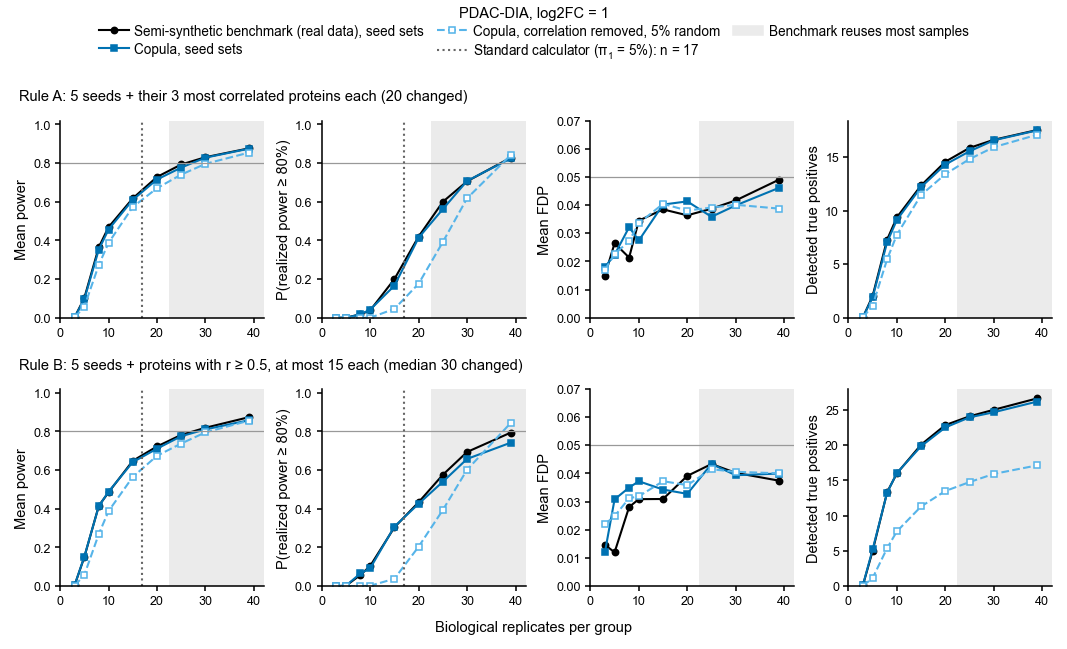

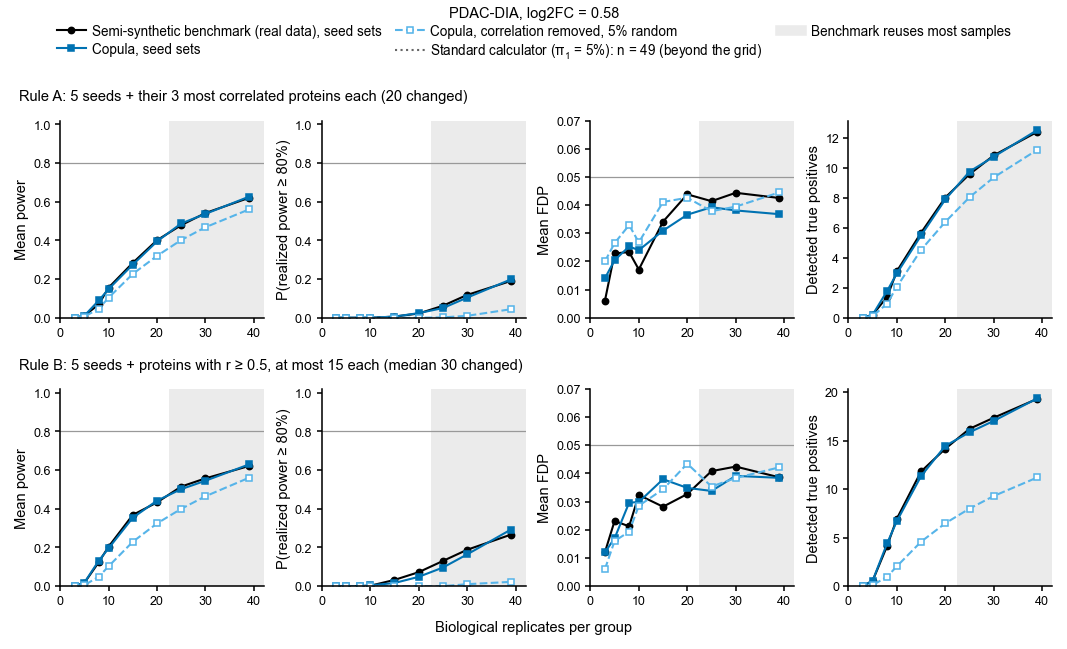

In [3]:
# PDAC-DIA seed pilot figures (needs cells 2 and 28)
seed_figure("PDAC_DIA", 1.0, "sample_size_seed_pilot_v5")
seed_figure("PDAC_DIA", 0.58, "sample_size_seed_pilot_lowfc_v5")

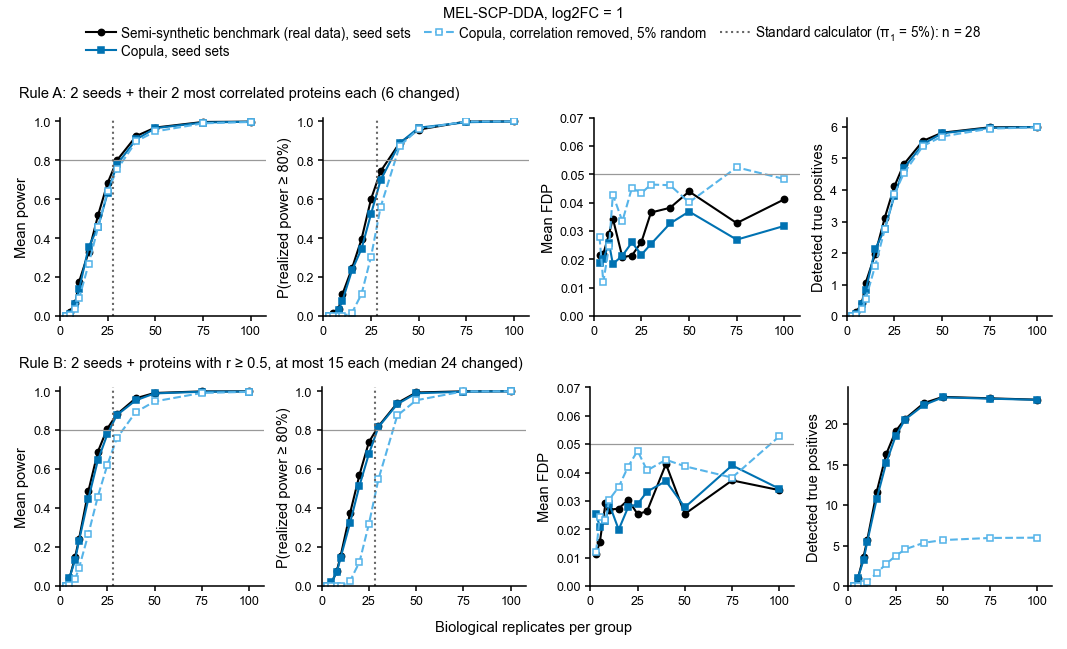

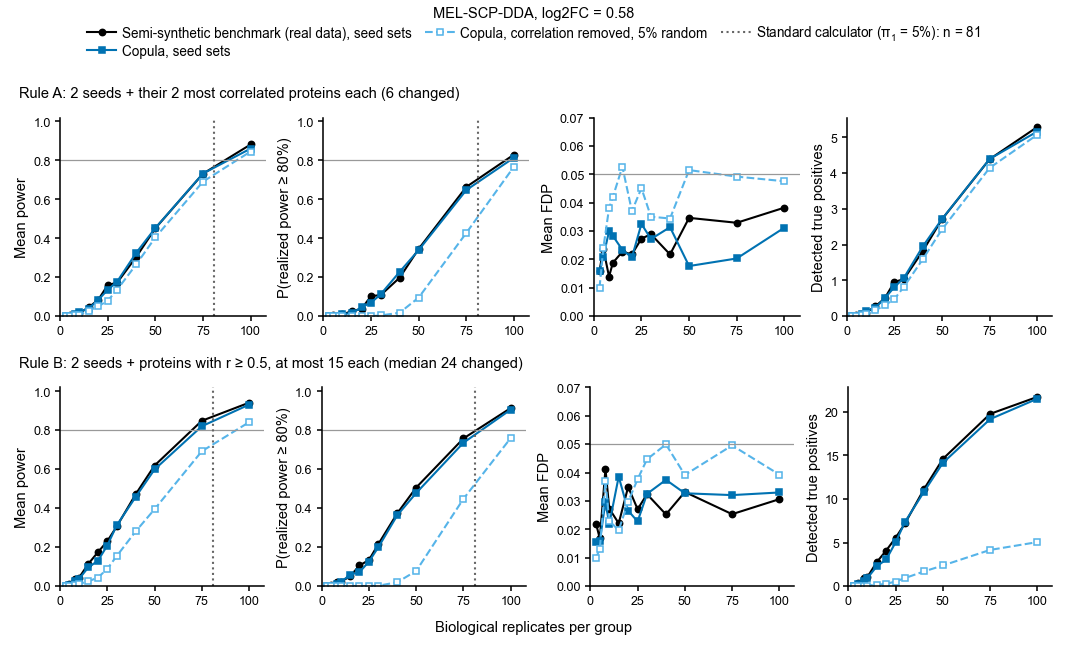

In [4]:
# MEL-SCP-DDA seed figures (needs cells 2 and 28). Results from MEL_case_study.ipynb cells 193-203.
seed_figure("MEL", 1.0, "sample_size_seed_mel_v2")
seed_figure("MEL", 0.58, "sample_size_seed_mel_lowfc_v2")


## Placement benchmark (PDAC-DIA)

Plan `plans/placement_benchmark.md` (Devon, 2026-10-19). Source: `PDAC_DIA/placement_*.csv`, written by `PDAC_case_study.ipynb` > "Placement benchmark" (cells 258–267). Semi-synthetic benchmark on the 79 null-ified PDAC-DIA samples (397 proteins). K proteins are DE in every replicate (K fixed across placements). Clustered: seed + partners with copula r > 0.5 (up to 15), repeated until K, one sign per cluster. Random: K uniform proteins, a sign each. Noise: correlated = the real samples; uncorrelated = each protein's values drawn independently (correlation removed, same per-protein values). 500 replicates per cell; Welch t-test + BH at FDR 0.05; success = TPR ≥ 0.8 and FDP ≤ 0.05. Above n = 20 the experiments reuse most of the 79 samples (shaded). Needs cell 2.

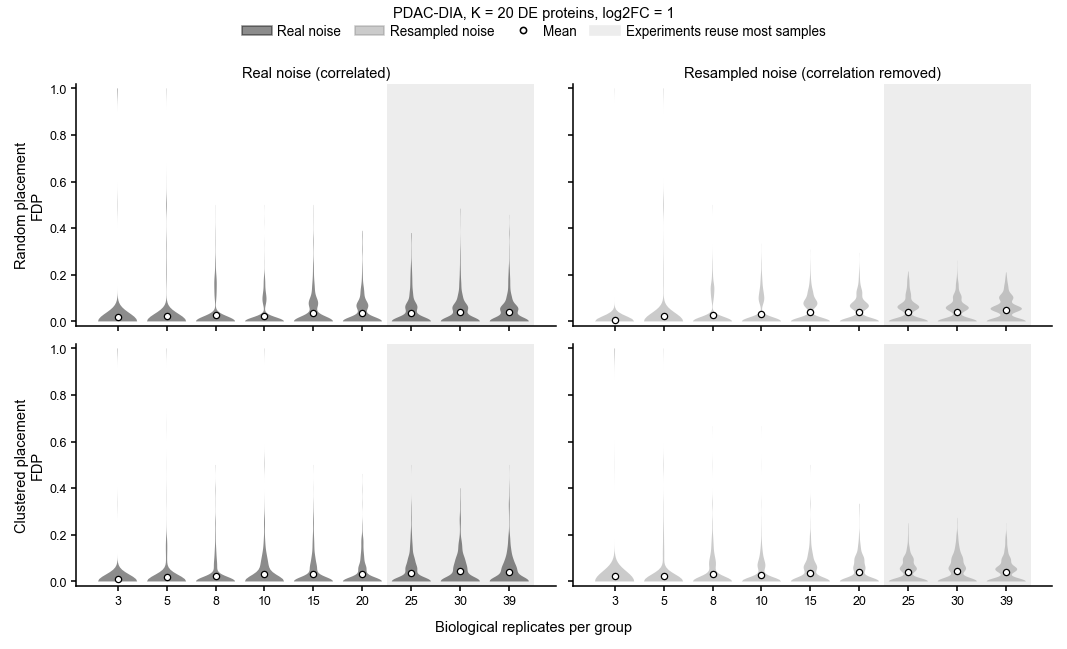

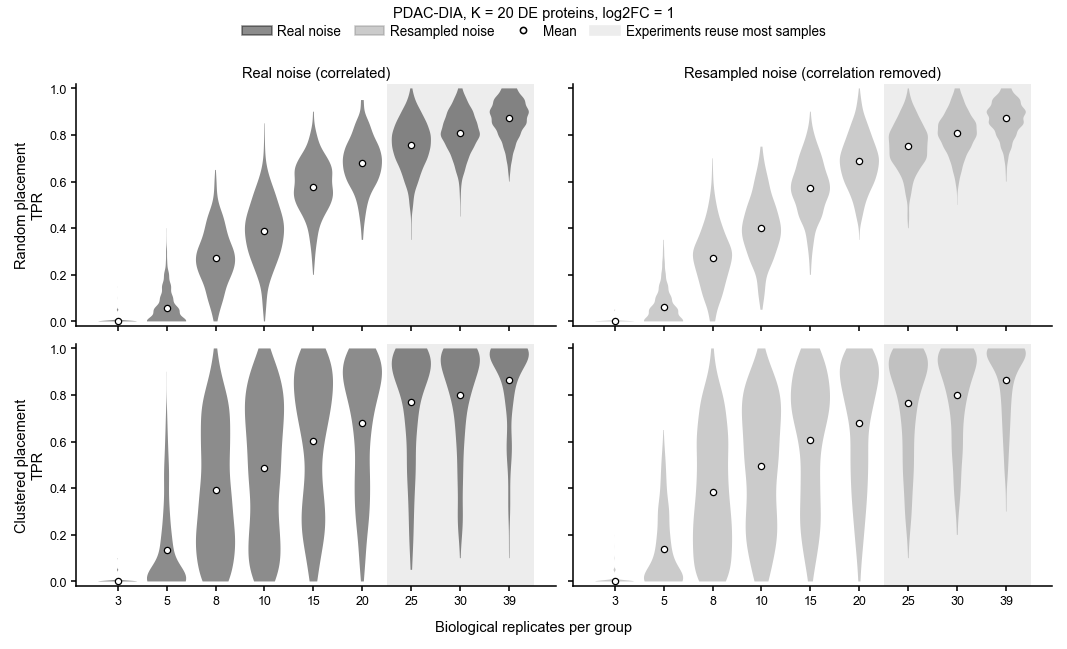

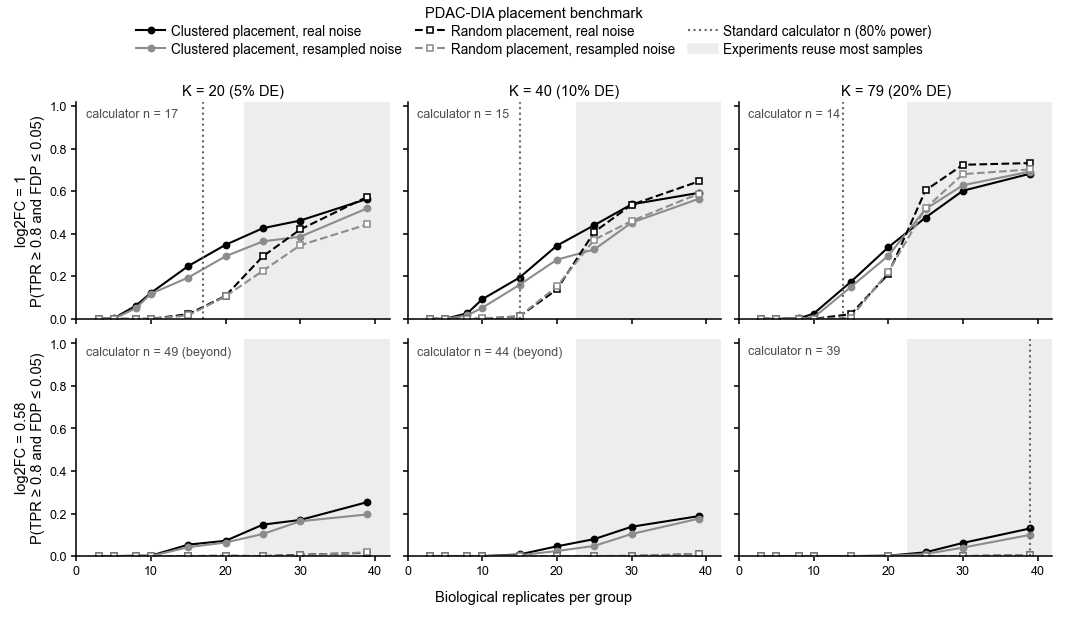

In [2]:
# Placement benchmark figures: violins of FDP and TPR (K = 20, log2FC = 1) and P(success) curves
PL_STYLES = {  # colour = noise, line/marker = placement
    ("clustered", "correlated"): dict(color="#000000", marker="o", linestyle="-"),
    ("clustered", "uncorrelated"): dict(color="#8C8C8C", marker="o", linestyle="-"),
    ("random", "correlated"): dict(color="#000000", marker="s", markerfacecolor="white", linestyle="--"),
    ("random", "uncorrelated"): dict(color="#8C8C8C", marker="s", markerfacecolor="white", linestyle="--"),
}
PL_NOISE = {"correlated": "Real noise (correlated)", "uncorrelated": "Resampled noise (correlation removed)"}
PL_PLACEMENT = {"random": "Random placement", "clustered": "Clustered placement"}
PL_REUSE_N = 20  # 79-sample pool: above n = 20 each replicate reuses most samples
pl_rep = pd.read_csv(os.path.join(RESULTS_DIR, "PDAC_DIA", "placement_replicates.csv"))
pl_sum = pd.read_csv(os.path.join(RESULTS_DIR, "PDAC_DIA", "placement_summary.csv"))
pl_calc = pd.read_csv(os.path.join(RESULTS_DIR, "PDAC_DIA", "placement_calculator.csv"))
pl_ns = sorted(pl_rep.n_per_group.unique())


def placement_violins(metric, ylabel, name, K=20, log2fc=1.0):
    sub = pl_rep[(pl_rep.K == K) & np.isclose(pl_rep.log2fc, log2fc)]
    fig, axes = plt.subplots(2, 2, figsize=(DOUBLE_COLUMN, 4.2), sharex=True, sharey=True)
    for r, placement in enumerate(PL_PLACEMENT):
        for c, noise in enumerate(PL_NOISE):
            ax = axes[r, c]
            d = sub[(sub.placement == placement) & (sub.correlation == noise)]
            vals = [d.loc[d.n_per_group == n, metric].to_numpy() for n in pl_ns]
            ax.axvspan(pl_ns.index(25) - 0.5, len(pl_ns) - 0.5, color="0.93", linewidth=0, zorder=0)
            parts = ax.violinplot(vals, positions=range(len(pl_ns)), widths=0.8, showextrema=False)
            for body in parts["bodies"]:
                body.set_facecolor(PL_STYLES[(placement, noise)]["color"])
                body.set_edgecolor("none")
                body.set_alpha(0.45)
            ax.plot(range(len(pl_ns)), [v.mean() for v in vals], color="white", marker="o", markersize=3,
                    markeredgecolor="black", markeredgewidth=0.6, linestyle="none")
            ax.set_xticks(range(len(pl_ns)), [str(n) for n in pl_ns])
            ax.set_ylim(-0.02, 1.02)
            if r == 0:
                ax.set_title(PL_NOISE[noise])
            if c == 0:
                ax.set_ylabel(f"{PL_PLACEMENT[placement]}\n{ylabel}")
    fig.supxlabel("Biological replicates per group")
    handles = [Patch(color="#000000", alpha=0.45, label="Real noise"), Patch(color="#8C8C8C", alpha=0.45, label="Resampled noise"),
               Line2D([], [], color="white", marker="o", markersize=3, markeredgecolor="black", linestyle="none", label="Mean"),
               Patch(color="0.93", label="Experiments reuse most samples")]
    fig.legend(handles=handles, loc="outside upper center", ncols=4, title=f"PDAC-DIA, K = {K} DE proteins, log2FC = {log2fc:g}")
    save_figure(fig, name)
    plt.show()


def placement_success(name):
    Ks, fcs = sorted(pl_sum.K.unique()), sorted(pl_sum.log2fc.unique(), reverse=True)
    fig, axes = plt.subplots(len(fcs), len(Ks), figsize=(DOUBLE_COLUMN, 4.0), sharex=True, sharey=True)
    for r, fc in enumerate(fcs):
        for c, K in enumerate(Ks):
            ax = axes[r, c]
            ax.axvspan(PL_REUSE_N + 2.5, max(pl_ns) + 3, color="0.93", linewidth=0, zorder=0)
            for (placement, noise), style in PL_STYLES.items():
                d = pl_sum[(pl_sum.K == K) & np.isclose(pl_sum.log2fc, fc) & (pl_sum.placement == placement)
                           & (pl_sum.correlation == noise)].sort_values("n_per_group")
                ax.plot(d.n_per_group, d.p_success, markersize=3, linewidth=1.0, **style)
            n_calc = pl_calc[(pl_calc.K == K) & np.isclose(pl_calc.log2fc, fc)].n_calculator.iloc[0]
            if n_calc <= max(pl_ns):
                ax.axvline(n_calc, color="0.4", linestyle=":", linewidth=1.0)
            ax.text(0.03, 0.97, f"calculator n = {n_calc}" + ("" if n_calc <= max(pl_ns) else " (beyond)"),
                    transform=ax.transAxes, ha="left", va="top", fontsize=6, color="0.3")
            ax.set_ylim(0, 1.02)
            ax.set_xlim(0, max(pl_ns) + 3)
            if r == 0:
                ax.set_title(f"K = {K} ({K / 397:.0%} DE)")
            if c == 0:
                ax.set_ylabel(f"log2FC = {fc:g}\nP(TPR ≥ 0.8 and FDP ≤ 0.05)")
    fig.supxlabel("Biological replicates per group")
    handles = [Line2D([], [], markersize=3, linewidth=1.0, label=f"{PL_PLACEMENT[p]}, {PL_NOISE[n].split(' (')[0].lower()}", **s)
               for (p, n), s in PL_STYLES.items()]
    handles += [Line2D([], [], color="0.4", linestyle=":", linewidth=1.0, label="Standard calculator n (80% power)"),
                Patch(color="0.93", label="Experiments reuse most samples")]
    fig.legend(handles=handles, loc="outside upper center", ncols=3, title="PDAC-DIA placement benchmark")
    save_figure(fig, name)
    plt.show()


placement_violins("fdp", "FDP", "placement_violins_fdp")
placement_violins("tpr", "TPR", "placement_violins_tpr")
placement_success("placement_success")


## Placement benchmark: ground truth vs Copula vs standard calculator

Plan `plans/placement_benchmark.md`, "Addition" (Devon, 2026-10-19). Real noise only. Ground truth = the semi-synthetic benchmark on the real null-ified samples (`placement_replicates.csv`, correlated rows). Copula = experiments drawn from a pool sampled from the Copula fitted to the same null-ified data. Calculator = (a) the standard calculator's n for 80% mean power (dotted line) and (b) its assumptions simulated: independent proteins sharing the median within-group variance (grey dashed). All methods use exactly the same truth assignments in every replicate. Success = TPR ≥ 0.8 and FDP ≤ 0.05; since BH at 0.05 gives a mean FDP of about 0.04–0.05, P(FDP ≤ 0.05) is about 0.7–0.8 even at full power, which caps P(success) below about 0.8. Needs cell 2.

In [2]:
# Ground truth vs Copula vs calculator: P(success) by n, rows = placement, columns = K
GTM_STYLES = {
    "ground_truth": dict(color="#000000", marker="o", linestyle="-", label="Ground truth (semi-synthetic, real noise)"),
    "copula": dict(color=SIMULATOR_STYLES["Copula"]["color"], marker="s", linestyle="-", label="Copula"),
    "calculator_sim": dict(color="0.45", marker="", linestyle="--", label="Calculator assumptions: shared variance (simulated)"),
    "perprotein_sim": dict(color=SIMULATOR_STYLES["Per-protein"]["color"], marker=SIMULATOR_STYLES["Per-protein"]["marker"],
                           linestyle=SIMULATOR_STYLES["Per-protein"]["linestyle"],
                           label="Calculator assumptions: per-protein variances (= Per-protein simulator)"),
}
GTM_PLACEMENT = {"random": "Random placement", "clustered": "Clustered placement"}
GTM_DATASETS = {"PDAC_DIA": dict(label="PDAC-DIA", n_proteins=397, reuse_n=20),
                "MEL": dict(label="MEL-SCP-DDA", n_proteins=124, reuse_n=None)}


def gtm_summary(dataset):
    gt = pd.read_csv(os.path.join(RESULTS_DIR, dataset, "placement_summary.csv"))
    gt = gt[gt.correlation == "correlated"].drop(columns="correlation").assign(method="ground_truth")
    sim = pd.read_csv(os.path.join(RESULTS_DIR, dataset, "placement_methods_summary.csv"))
    perprotein = os.path.join(RESULTS_DIR, dataset, "placement_perprotein_summary.csv")  # Addition 2
    if os.path.exists(perprotein):
        sim = pd.concat([sim, pd.read_csv(perprotein)], ignore_index=True)
    calc = pd.read_csv(os.path.join(RESULTS_DIR, dataset, "placement_calculator.csv"))
    return pd.concat([gt, sim], ignore_index=True), calc


def methods_success(dataset, log2fc, name, metric="p_success", ylabel="P(TPR ≥ 0.8 and FDP ≤ 0.05)"):
    cfg = GTM_DATASETS[dataset]
    summary, calc = gtm_summary(dataset)
    summary = summary[np.isclose(summary.log2fc, log2fc)]
    Ks = sorted(summary.K.unique())
    gt_max = summary[summary.method == "ground_truth"].n_per_group.max()
    n_max = summary.n_per_group.max()
    fig, axes = plt.subplots(2, len(Ks), figsize=(DOUBLE_COLUMN, 4.0), sharex=True, sharey=True)
    for r, placement in enumerate(["random", "clustered"]):
        for c, K in enumerate(Ks):
            ax = axes[r, c]
            if cfg["reuse_n"] is not None:
                ax.axvspan(cfg["reuse_n"] + 2.5, gt_max + 1.5, color="0.92", linewidth=0, zorder=0)
            if gt_max < n_max:
                ax.axvspan(gt_max + 1.5, n_max * 1.05, color="0.97", linewidth=0, zorder=0)
            for method, style in GTM_STYLES.items():
                d = summary[(summary.method == method) & (summary.placement == placement) & (summary.K == K)]
                if d.empty:
                    continue
                d = d.sort_values("n_per_group")
                ax.plot(d.n_per_group, d[metric], markersize=3, linewidth=1.0, **style)
            n_calc = calc[(calc.K == K) & np.isclose(calc.log2fc, log2fc)].n_calculator.iloc[0]
            ax.axvline(n_calc, color="0.4", linestyle=":", linewidth=1.0)
            ax.text(0.97, 0.04, f"calculator n = {n_calc}", transform=ax.transAxes, ha="right", va="bottom",
                    fontsize=6, color="0.3")
            ax.set_ylim(0, 1.02)
            ax.set_xlim(0, n_max * 1.05)
            if r == 0:
                ax.set_title(f"K = {K} ({K / cfg['n_proteins']:.0%} DE)")
            if c == 0:
                ax.set_ylabel(f"{GTM_PLACEMENT[placement]}\n{ylabel}")
    fig.supxlabel("Biological replicates per group")
    handles = [Line2D([], [], markersize=3, linewidth=1.0, **s) for m, s in GTM_STYLES.items()
               if (summary.method == m).any()]
    handles.append(Line2D([], [], color="0.4", linestyle=":", linewidth=1.0, label="Standard calculator n (80% mean power)"))
    if cfg["reuse_n"] is not None:
        handles.append(Patch(color="0.92", label="Ground truth reuses most samples"))
    if gt_max < n_max:
        handles.append(Patch(color="0.97", label="No ground truth (simulated only)"))
    fig.legend(handles=handles, loc="outside upper center", ncols=2, title=f"{cfg['label']}, log2FC = {log2fc:g}")
    save_figure(fig, name)
    plt.show()


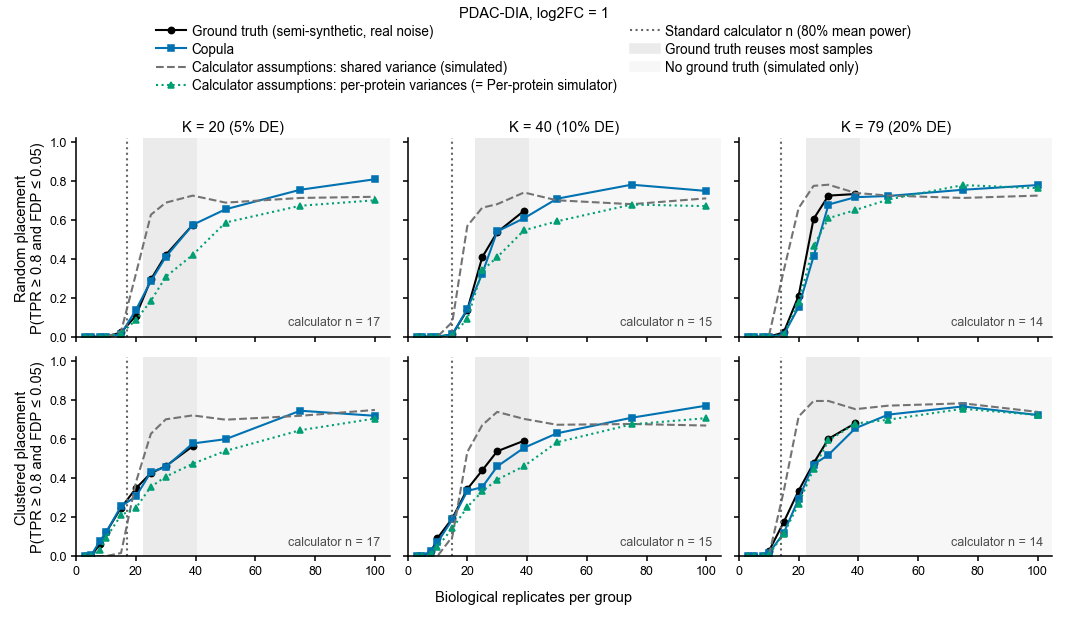

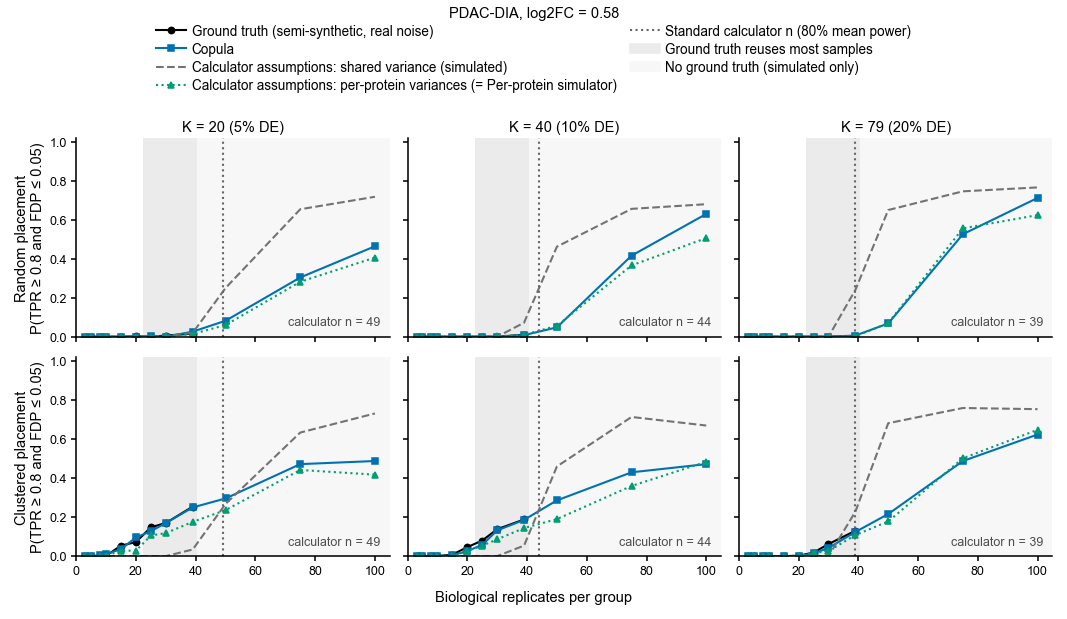

In [3]:
# PDAC-DIA (needs cells 2 and 35)
methods_success("PDAC_DIA", 1.0, "placement_methods_success_v2")
methods_success("PDAC_DIA", 0.58, "placement_methods_success_lowfc_v2")


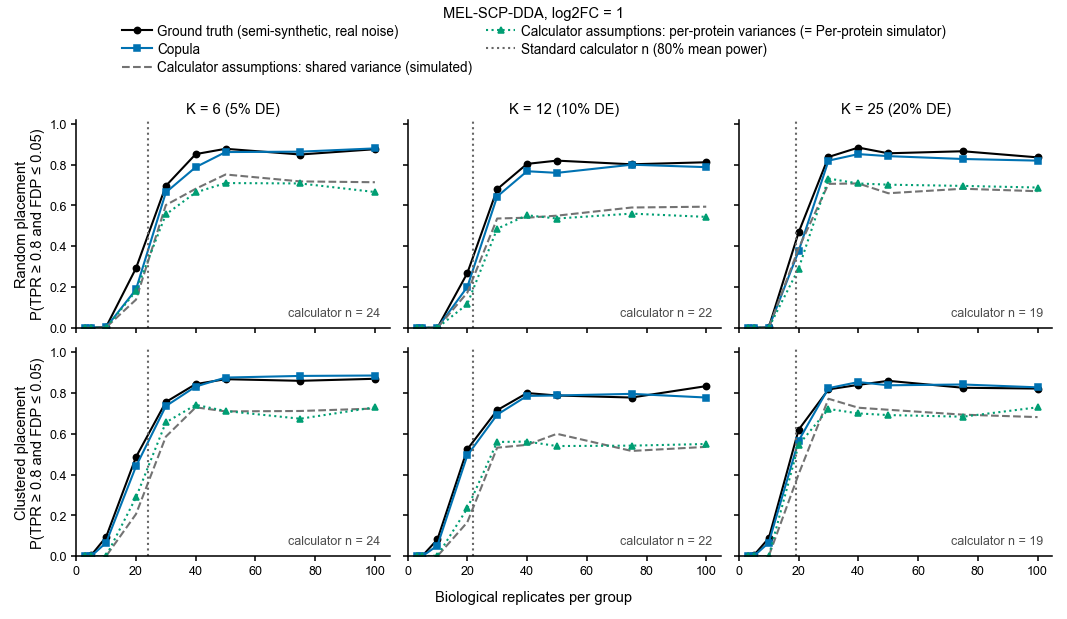

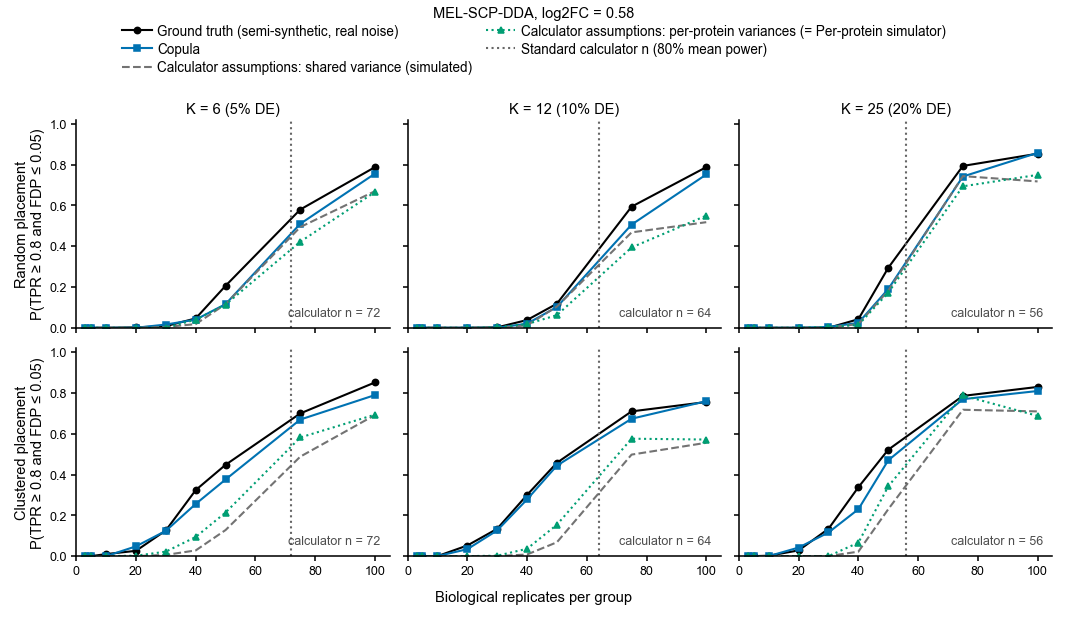

In [3]:
# MEL-SCP-DDA (needs cells 2 and 35). Results from MEL_case_study.ipynb cells 157-167 (589 cells, R16 runs dropped).
methods_success("MEL", 1.0, "placement_methods_success_mel_v2")
methods_success("MEL", 0.58, "placement_methods_success_mel_lowfc_v2")


## Paper figure: sample size with clustered DE proteins (MEL-SCP-DDA and PDAC-DIA)

Final versions requested by Devon (2026-10-20). Clustered placement only; columns K = 5% and 10% of the proteins DE; rows log2FC = 0.58 and 1. Lines: ground truth (semi-synthetic benchmark on the real null-ified data), Per-protein (independent proteins, each with its own variance), Copula; all on the same truth assignments, 500 replicates each. y = P(success) = P(TPR ≥ 0.8 and FDP ≤ 0.05), the probability that one experiment detects at least 80% of the truly DE proteins with a false discovery proportion of at most 5% (Welch t-test + BH at FDR 0.05; Devon, 2026-10-20). Because BH at 0.05 gives a mean FDP of about 0.04–0.05, P(FDP ≤ 0.05) stays below 1 even at full power, so the curves level off below 1. Dotted line: the standard calculator's n for 80% mean power (MSstats designSampleSize formula, median variance, π₁ = K / proteins). PDAC-DIA: the ground truth stops at n = 39 (79 samples) and reuses most samples above n = 20 (shaded). Sources: `<DS>/placement_replicates.csv` (correlated rows), `placement_methods_replicates.csv` (copula), `placement_perprotein_replicates.csv`, `placement_calculator.csv`. Needs cell 2.

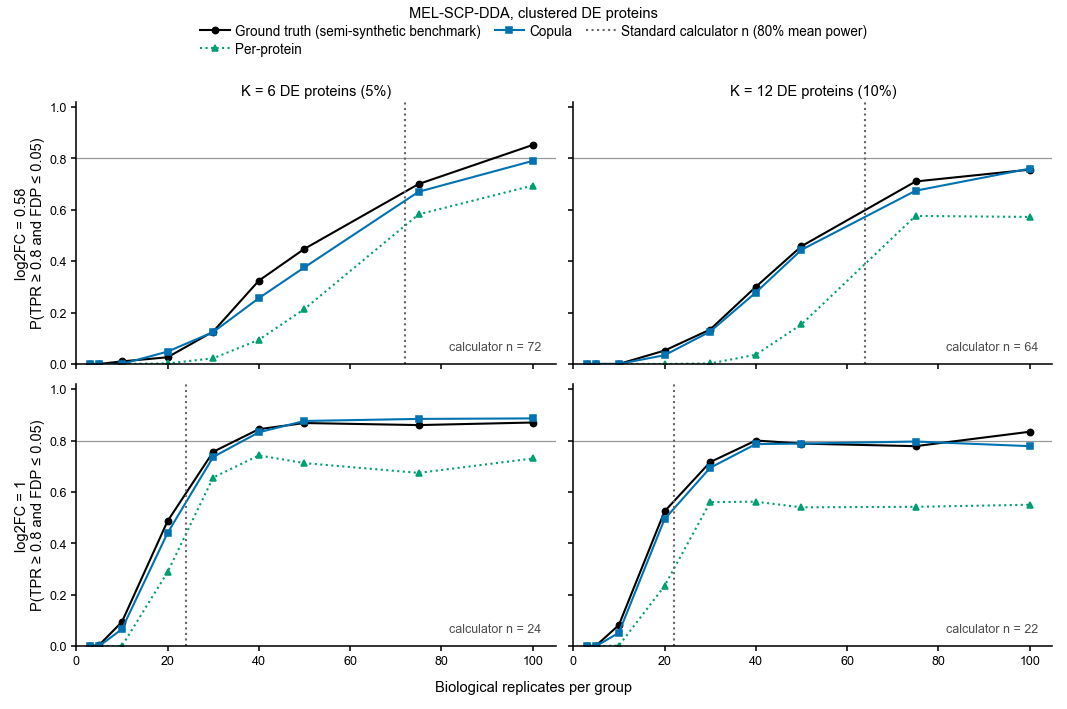

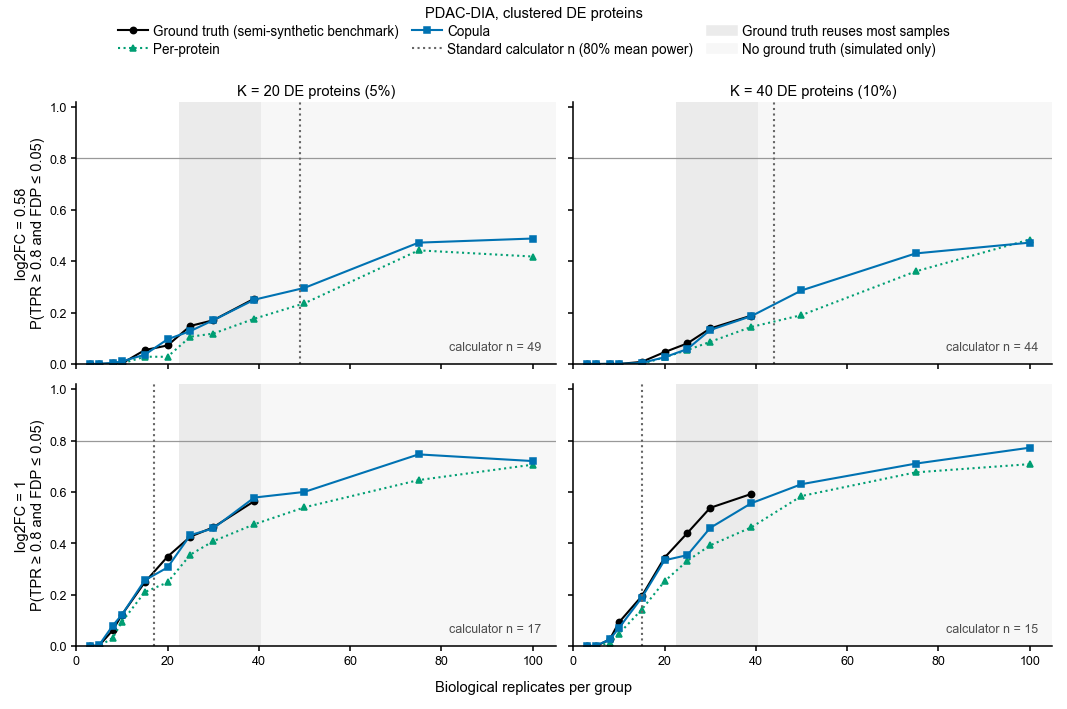

In [2]:
# Paper figures: P(TPR >= 0.8 and FDP <= 0.05) by n for clustered placement; columns = K, rows = log2FC
PAPER_SS_STYLES = {
    "ground_truth": dict(SIMULATOR_STYLES["Experimental"], label="Ground truth (semi-synthetic benchmark)"),
    "perprotein_sim": dict(SIMULATOR_STYLES["Per-protein"], label="Per-protein"),
    "copula": dict(SIMULATOR_STYLES["Copula"], label="Copula"),
}
PAPER_SS_DATASETS = {
    "MEL": dict(label="MEL-SCP-DDA", n_proteins=124, Ks=[6, 12], reuse_n=None),
    "PDAC_DIA": dict(label="PDAC-DIA", n_proteins=397, Ks=[20, 40], reuse_n=20),
}


def paper_ss_curves(dataset, placement="clustered"):
    """P(success) = P(TPR >= 0.8 and FDP <= 0.05) per method, K, log2FC and n, from the per-replicate results."""
    path = lambda f: os.path.join(RESULTS_DIR, dataset, f)
    gt = pd.read_csv(path("placement_replicates.csv"))
    gt = gt[gt.correlation == "correlated"].assign(method="ground_truth")
    reps = pd.concat([gt, pd.read_csv(path("placement_methods_replicates.csv")),
                      pd.read_csv(path("placement_perprotein_replicates.csv"))], ignore_index=True)
    reps = reps[(reps.placement == placement) & reps.method.isin(PAPER_SS_STYLES)]
    curves = (reps.assign(hit=(reps.tpr >= 0.8) & (reps.fdp <= 0.05))
              .groupby(["method", "K", "log2fc", "n_per_group"]).hit.agg(["mean", "size"]).reset_index())
    assert (curves["size"] == 500).all(), "expected 500 replicates per point"
    return curves.rename(columns={"mean": "p_success"}), pd.read_csv(path("placement_calculator.csv"))


def paper_ss_figure(dataset, name):
    cfg = PAPER_SS_DATASETS[dataset]
    curves, calc = paper_ss_curves(dataset)
    gt_max = curves[curves.method == "ground_truth"].n_per_group.max()
    n_max = curves.n_per_group.max()
    fcs = [0.58, 1.0]
    fig, axes = plt.subplots(len(fcs), len(cfg["Ks"]), figsize=(DOUBLE_COLUMN, 4.6), sharex=True, sharey=True)
    for r, fc in enumerate(fcs):
        for c, K in enumerate(cfg["Ks"]):
            ax = axes[r, c]
            if cfg["reuse_n"] is not None:
                ax.axvspan(cfg["reuse_n"] + 2.5, gt_max + 1.5, color="0.92", linewidth=0, zorder=0)
            if gt_max < n_max:
                ax.axvspan(gt_max + 1.5, n_max * 1.05, color="0.97", linewidth=0, zorder=0)
            ax.axhline(0.8, color="0.6", linewidth=0.6)
            for method, style in PAPER_SS_STYLES.items():
                d = curves[(curves.method == method) & (curves.K == K) & np.isclose(curves.log2fc, fc)]
                d = d.sort_values("n_per_group")
                ax.plot(d.n_per_group, d.p_success, markersize=3, linewidth=1.0, **style)
            n_calc = calc[(calc.K == K) & np.isclose(calc.log2fc, fc)].n_calculator.iloc[0]
            ax.axvline(n_calc, color="0.4", linestyle=":", linewidth=1.0)
            ax.text(0.97, 0.04, f"calculator n = {n_calc}", transform=ax.transAxes, ha="right", va="bottom",
                    fontsize=6, color="0.3")
            ax.set_ylim(0, 1.02)
            ax.set_xlim(0, n_max * 1.05)
            if r == 0:
                ax.set_title(f"K = {K} DE proteins ({K / cfg['n_proteins']:.0%})")
            if c == 0:
                ax.set_ylabel(f"log2FC = {fc:g}\nP(TPR ≥ 0.8 and FDP ≤ 0.05)")
    fig.supxlabel("Biological replicates per group")
    handles = [Line2D([], [], markersize=3, linewidth=1.0, **s) for s in PAPER_SS_STYLES.values()]
    handles.append(Line2D([], [], color="0.4", linestyle=":", linewidth=1.0, label="Standard calculator n (80% mean power)"))
    if cfg["reuse_n"] is not None:
        handles.append(Patch(color="0.92", label="Ground truth reuses most samples"))
    if gt_max < n_max:
        handles.append(Patch(color="0.97", label="No ground truth (simulated only)"))
    fig.legend(handles=handles, loc="outside upper center", ncols=3,
               title=f"{cfg['label']}, clustered DE proteins")
    save_figure(fig, name)
    plt.show()


paper_ss_figure("MEL", "sample_size_placement_mel_v2")
paper_ss_figure("PDAC_DIA", "sample_size_placement_pdac_v2")


# Legacy simulations and Random Forest

The original exploratory code of this notebook, not used in the paper (see the note in cell 0).

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from protmapper import uniprot_client
from indra.databases import hgnc_client

from MSquantSim.simulate import simulate_using_copula, simulate_using_tvae, \
    simulate_using_per_protein
from causomic.graph_construction.utils import get_neighbor_network
from causomic.graph_construction.indra_queries import get_ids, format_query_results
from sklearn.impute import KNNImputer

import warnings
warnings.filterwarnings('ignore')

import os
from indra_cogex.client import Neo4jClient

client = Neo4jClient(url=os.getenv("API_URL"), 
                        auth=(os.getenv("USER"), 
                            os.getenv("PASSWORD"))
                    )

/Users/kohler.d/miniconda3/envs/MSquantSim_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO: [2025-12-17 09:45:25] indra_cogex.client.neo4j_client - Connected to neo4j graph at bolt://indra-cogex-lb-b954b684556c373c.elb.us-east-1.amazonaws.com:7687


In [2]:
def hgnc_converter(id, mnemonic_id=False):
    if mnemonic_id:
        uniprot_id = uniprot_client.get_id_from_mnemonic(id)
    else:
        uniprot_id = id
    hgnc_id = uniprot_client.get_hgnc_id(uniprot_id)
    hgnc_name = hgnc_client.get_hgnc_name(hgnc_id)
    return hgnc_name

# CRC

## Load and prepare data

In [4]:
crc_input = pd.read_csv('../../data/CRC_data/CRC_training_protein_level_data.csv')
crc_validation_input = pd.read_csv('../../data/CRC_data/CRC_validation_protein_level_data.csv')
crc_input.head()

,Run,A1AG2,AFM,AHSG,ANT3,AOC3,APOB,ATRN,BTD,C20orf3,...,SERPINA1,SERPINA3,SERPINA6,SERPINA7,THBS1,TIMP1,VTN,VWF,Condition,BioReplicate
0,CRC_P1A10,14.238157,16.103019,19.951792,17.207936,10.032169,15.544774,14.383388,16.283071,10.667779,...,18.061091,14.218036,15.796849,13.581848,13.995686,11.578754,12.081352,10.661031,CRC,CRC_P1A10
1,CRC_P1A2,15.024111,16.020714,19.715919,17.297900,9.034144,15.131883,13.981723,16.249189,10.703279,...,17.610188,14.832327,15.815397,13.138445,13.707714,11.960974,12.838407,10.778432,CRC,CRC_P1A2
2,CRC_P1A4,15.631364,16.143800,19.710849,17.596254,10.381880,15.955302,14.635355,16.499158,11.183873,...,18.539972,15.308726,16.401770,13.742330,15.636962,12.155842,12.313155,11.185271,CRC,CRC_P1A4
3,CRC_P1A6,15.401365,16.276415,19.704377,17.422504,9.502960,15.714932,14.060700,16.277732,9.972982,...,17.401414,14.254241,16.310491,13.936894,15.517268,12.379265,10.679166,10.887855,CRC,CRC_P1A6
4,CRC_P1B12,16.003158,16.958207,20.420334,17.988199,9.648502,16.247330,14.203595,16.541422,12.581556,...,17.448008,16.231911,16.485833,14.167134,15.129106,12.169116,14.506106,11.254175,CRC,CRC_P1B12


In [8]:
len(crc_input.columns)

70

In [45]:
# Split into health and disease
crc_healthy = crc_input[crc_input['Condition'] == 'Healthy'].drop(columns=['Condition', 'Run', 'BioReplicate'])
crc_disease = crc_input[crc_input['Condition'] == 'CRC'].drop(columns=['Condition', 'Run', 'BioReplicate'])

## Copula

### Single simulation

In [46]:
copula_sim_healthy = simulate_using_copula(
    crc_healthy, num_simulations=1, 
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_disease = simulate_using_copula(
    crc_disease, num_simulations=1, 
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

INFO: [2025-12-16 12:34:56] copulas.multivariate.gaussian - Fitting GaussianMultivariate()
INFO: [2025-12-16 12:35:04] copulas.multivariate.gaussian - Fitting GaussianMultivariate()


### Multiple simulations

In [ ]:
n_sims = 10

copula_sim_healthy = simulate_using_copula(
    crc_healthy, num_simulations=n_sims, 
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_disease = simulate_using_copula(
    crc_disease, num_simulations=n_sims, 
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

## TVAE

### Single simulation

In [ ]:
tvae_sim_healthy = simulate_using_tvae(
    crc_healthy, None, num_simulations=1,
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_disease = simulate_using_tvae(
    crc_disease, None, num_simulations=1,
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

### Multiple simulations

In [ ]:
n_sims = 10

tvae_sim_healthy = simulate_using_tvae(
    crc_healthy, None, num_simulations=n_sims,
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_disease = simulate_using_tvae(
    crc_disease, None, num_simulations=n_sims,
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

## Per-protein

### Single simulation

In [ ]:
pprotein_sim_healthy = simulate_using_per_protein(
    crc_healthy, num_simulations=1,
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_disease = simulate_using_per_protein(
    crc_disease, num_simulations=1,
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

### Multiple simulations

In [ ]:
n_sims = 10

pprotein_sim_healthy = simulate_using_per_protein(
    crc_healthy, num_simulations=n_sims,
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_disease = simulate_using_per_protein(
    crc_disease, num_simulations=n_sims,
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

# MEL

## Load and prepare data

In [28]:
mel_input = pd.read_csv('../../data/MEL_data/MEL_protein_level_data.csv')
mel_input = mel_input.loc[:, ~mel_input.columns.str.contains(';', na=False)]
mel_input.columns = [col.split('|')[1] if '|' in col else col for col in mel_input.columns]
mel_input = mel_input.drop(columns=["Run", "Channel"])

mel_input.columns = [hgnc_converter(i, mnemonic_id=False) if i != "Condition" \
    else "Condition" for i in mel_input.columns]
mel_input.head()

,Condition,ARHGAP10,EFCAB5,FAM186A,ZBTB42,NACA,CROCC2,ACOT7,MYO1C,SNAP23,...,TC2N,MED17,ARGLU1,BTG4,NAGK,SHROOM4,UTP18,ABHD8,BABAM1,HDAC11
0,u,10.449841,11.267802,10.620656,12.056047,10.616000,8.971095,7.622955,9.967160,10.002026,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,u,9.988900,9.341027,10.188457,11.560510,10.587988,9.142974,7.911131,9.644867,9.406374,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,m,9.731853,8.977844,10.933736,13.109581,10.729755,10.703360,8.243595,10.009776,9.323197,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,m,10.151383,9.964322,10.468290,13.302292,10.721968,NaN,8.699114,9.753093,10.364373,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,m,10.675715,10.823538,11.139793,12.791292,10.218707,7.363879,7.709675,9.950416,10.489982,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Filter data using missing values and INDRA network

In [29]:
# Count missing values per column
missing_counts = mel_input.isna().sum()
missing_percentages = (missing_counts / len(mel_input))

print(f"Columns with missing values: {(missing_counts > 0).sum()}")
print(f"Total missing values: {missing_counts.sum()}")

# Remove columns with more than 50% missing values
threshold = 0.5
cols_to_keep = missing_percentages[missing_percentages <= threshold].index
mel_input = mel_input[cols_to_keep]

print(f"\nColumns after filtering: {len(mel_input.columns)}")
print(f"Columns removed: {len(missing_percentages) - len(cols_to_keep)}")

Columns with missing values: 3139
Total missing values: 1218425

Columns after filtering: 1148
Columns removed: 1992


In [31]:
len(mel_input.columns) - 1

1147

In [29]:
test_network = format_query_results(get_neighbor_network(
    nodes=query_ids,
    client=client,
    relation=["IncreaseAmount", "DecreaseAmount"],
    upstream=True,
    downstream=True,
    minimum_evidence_count=5,
    filter_all_nodes=True))

filtered = test_network.loc[:, ["source", "target"]].drop_duplicates()

G = nx.DiGraph()
for i in range(len(filtered)):
    G.add_edge(filtered.iloc[i]["source"], filtered.iloc[i]["target"])

components = list(nx.weakly_connected_components(G))
max_component = max(components, key=len)
print(f"Largest connected component size: {len(max_component)} nodes")

cols = [c for c in mel_input.columns if (c == 'Condition' or c in max_component)]
mel_input = mel_input.loc[:, cols]

Largest connected component size: 124 nodes


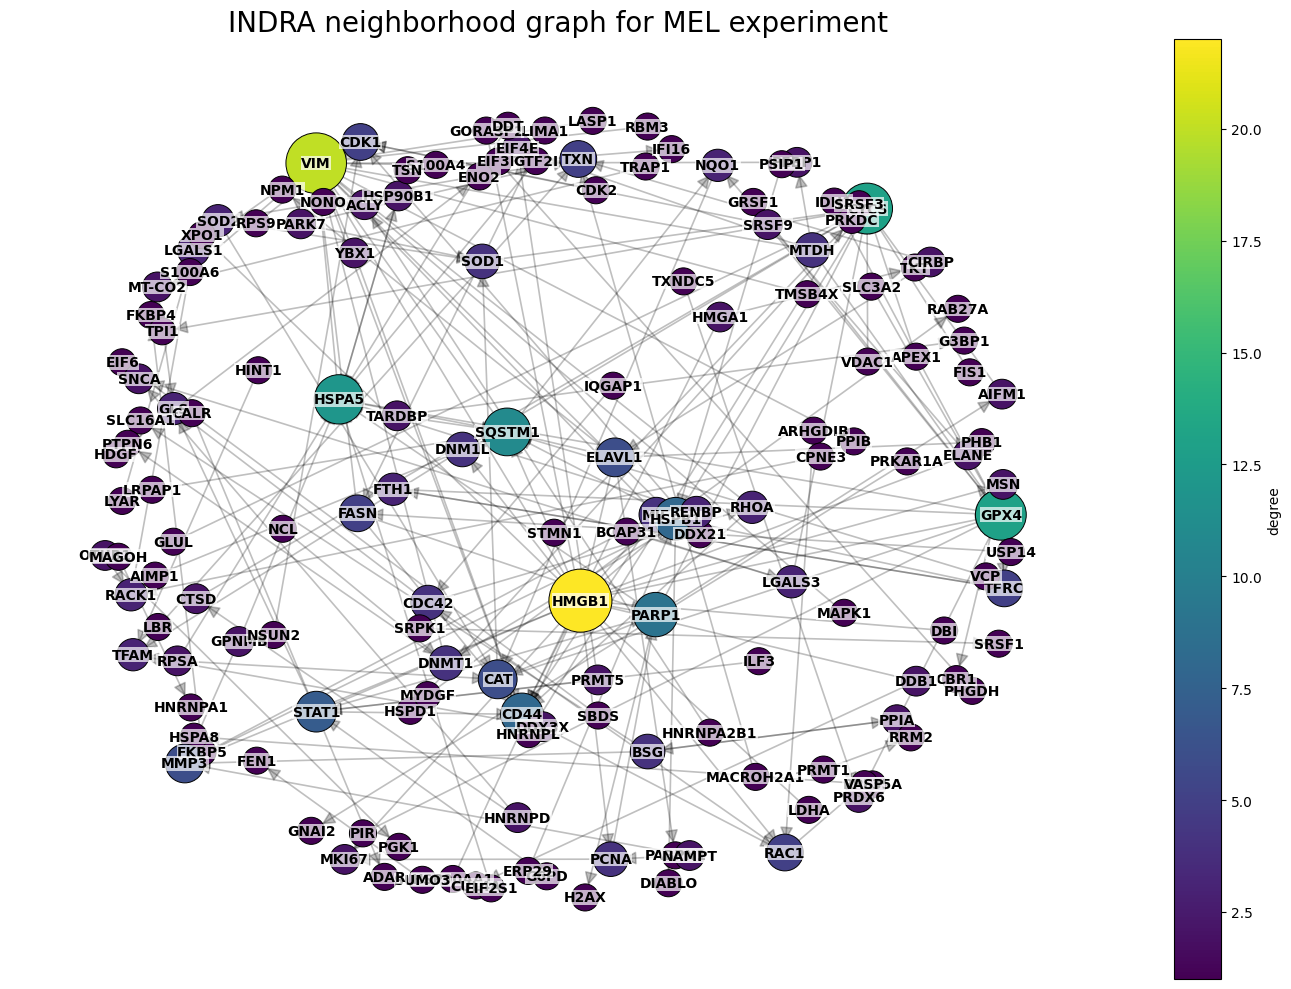

In [30]:
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42, k=.8)  # slightly more spacing
deg = dict(G.degree())
# Bigger nodes overall
node_sizes = [300 + deg[n] * 80 for n in G.nodes()]
node_colors = [deg[n] for n in G.nodes()]
nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.25,
    arrowsize=20,
    width=1.2
)
nodes = nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap="viridis",
    edgecolors="black",
    linewidths=0.7
)
nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight="bold",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.7,
        pad=0.2
    )
)
plt.colorbar(nodes, label="degree")
plt.title("INDRA neighborhood graph for MEL experiment", fontsize=20)
plt.axis("off")
plt.tight_layout()
plt.show()

### Impute missing values

In [ ]:
# Keep original column order
orig_cols = mel_input.columns.tolist()

# Split numeric and non-numeric columns
numeric_cols = [c for c in orig_cols if pd.api.types.is_numeric_dtype(mel_input[c])]
non_numeric_cols = [c for c in orig_cols if c not in numeric_cols]

# Report missing values before imputation
print("Missing values before imputation (numeric cols):")
print(mel_input[numeric_cols].isna().sum().sum())

# KNN imputation
imputer = KNNImputer(n_neighbors=5, weights="uniform")
imputed_array = imputer.fit_transform(mel_input[numeric_cols])

# Build imputed DataFrame and restore original column order
imputed_numeric = pd.DataFrame(imputed_array, columns=numeric_cols, index=mel_input.index)
mel_input = pd.concat([mel_input[non_numeric_cols], imputed_numeric], axis=1)[orig_cols]

# Report missing values after imputation
print("\nMissing values after imputation (numeric cols):")
print(mel_input[numeric_cols].isna().sum().sum())

Missing values before imputation (numeric cols):
10496

Missing values after imputation (numeric cols):
0


In [32]:
# Split into health and disease
mel_healthy = mel_input[mel_input['Condition'] == "u"].drop(columns=['Condition'])
mel_disease = mel_input[mel_input['Condition'] == "m"].drop(columns=['Condition'])

In [34]:
mel_healthy.head()

,DDX3X,PIR,PRMT5,XPO1,CPNE3,MACROH2A1,PSIP1,IDH1,GLS,AIFM1,...,DNM1L,CDK1,GLUL,GPX4,USP14,RBM3,LASP1,DIABLO,LIMA1,GRSF1
0,9.099064,9.783696,10.502268,8.909095,10.115059,8.794337,8.523487,9.653396,8.810845,8.511018,...,8.469644,10.089932,10.645780,8.531974,9.347187,9.837232,10.311711,14.183632,11.588486,9.072424
1,10.010491,9.360264,9.751682,9.207139,10.093208,8.010631,9.221851,9.460861,8.871287,7.944545,...,8.323297,9.904290,10.687988,8.902241,8.817976,10.158084,10.412729,13.672828,11.456852,8.859214
8,9.346990,10.553571,10.360573,9.533039,10.169222,9.798709,9.563130,10.585194,7.939550,8.677462,...,8.031204,9.789540,10.857560,9.323271,9.299829,10.869589,10.121980,14.148033,11.839861,9.338212
9,9.567772,10.928405,10.003267,9.198541,9.921314,9.417135,8.818566,9.760575,9.492402,8.364762,...,8.607676,9.915853,10.662570,9.095007,9.020460,10.758311,10.514252,13.700885,11.576995,9.157730
10,9.256519,9.030232,9.644022,8.593391,8.948854,8.499681,8.367662,9.819181,8.866103,8.518947,...,7.968344,9.525700,10.628336,8.519930,9.238446,10.030480,10.012083,13.867745,11.717314,9.357831


## Copula

### Single simulation

In [35]:
copula_sim_mel_healthy_single = simulate_using_copula(
    mel_healthy, num_simulations=1, 
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_mel_disease_single = simulate_using_copula(
    mel_disease, num_simulations=1, 
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

INFO: [2025-12-16 10:10:15] copulas.multivariate.gaussian - Fitting GaussianMultivariate()
INFO: [2025-12-16 10:10:36] copulas.multivariate.gaussian - Fitting GaussianMultivariate()


### Multiple simulations

In [ ]:
n_sims = 10

copula_sim_mel_healthy_multi = simulate_using_copula(
    mel_healthy, num_simulations=n_sims, 
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_mel_disease_multi = simulate_using_copula(
    mel_disease, num_simulations=n_sims, 
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=100
)

100%|██████████| 10/10 [00:20<00:00,  2.08s/it]10 [00:00<?, ?it/s]






100%|██████████| 10/10 [00:16<00:00,  1.63s/it]


## TVAE

### Single simulation

In [37]:
tvae_sim_mel_healthy_single = simulate_using_tvae(
    mel_healthy, None, num_simulations=1,
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_mel_disease_single = simulate_using_tvae(
    mel_disease, None, num_simulations=1,
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

INFO: [2025-12-16 10:12:27] sdv.metadata.single_table - Detected metadata:
INFO: [2025-12-16 10:12:27] sdv.metadata.single_table - {
    "METADATA_SPEC_VERSION": "SINGLE_TABLE_V1",
    "columns": {
        "DDX3X": {
            "sdtype": "numerical"
        },
        "PIR": {
            "sdtype": "numerical"
        },
        "PRMT5": {
            "sdtype": "numerical"
        },
        "XPO1": {
            "sdtype": "numerical"
        },
        "CPNE3": {
            "sdtype": "numerical"
        },
        "MACROH2A1": {
            "sdtype": "numerical"
        },
        "PSIP1": {
            "sdtype": "numerical"
        },
        "IDH1": {
            "sdtype": "numerical"
        },
        "GLS": {
            "sdtype": "numerical"
        },
        "AIFM1": {
            "sdtype": "numerical"
        },
        "LDHA": {
            "sdtype": "numerical"
        },
        "MT-CO2": {
            "sdtype": "numerical"
        },
        "SOD1": {
            "sdtyp

### Multiple simulations

In [38]:
n_sims = 10

tvae_sim_mel_healthy_multi = simulate_using_tvae(
    mel_healthy, None, num_simulations=n_sims,
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_mel_disease_multi = simulate_using_tvae(
    mel_disease, None, num_simulations=n_sims,
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

INFO: [2025-12-16 10:13:35] sdv.metadata.single_table - Detected metadata:
INFO: [2025-12-16 10:13:35] sdv.metadata.single_table - {
    "METADATA_SPEC_VERSION": "SINGLE_TABLE_V1",
    "columns": {
        "DDX3X": {
            "sdtype": "numerical"
        },
        "PIR": {
            "sdtype": "numerical"
        },
        "PRMT5": {
            "sdtype": "numerical"
        },
        "XPO1": {
            "sdtype": "numerical"
        },
        "CPNE3": {
            "sdtype": "numerical"
        },
        "MACROH2A1": {
            "sdtype": "numerical"
        },
        "PSIP1": {
            "sdtype": "numerical"
        },
        "IDH1": {
            "sdtype": "numerical"
        },
        "GLS": {
            "sdtype": "numerical"
        },
        "AIFM1": {
            "sdtype": "numerical"
        },
        "LDHA": {
            "sdtype": "numerical"
        },
        "MT-CO2": {
            "sdtype": "numerical"
        },
        "SOD1": {
            "sdtyp

## Per-protein

### Single simulation

In [39]:
pprotein_sim_mel_healthy_single = simulate_using_per_protein(
    mel_healthy, num_simulations=1,
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_mel_disease_single = simulate_using_per_protein(
    mel_disease, num_simulations=1,
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

### Multiple simulations

In [40]:
n_sims = 10

pprotein_sim_mel_healthy_multi = simulate_using_per_protein(
    mel_healthy, num_simulations=n_sims,
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_mel_disease_multi = simulate_using_per_protein(
    mel_disease, num_simulations=n_sims,
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)






100%|██████████| 10/10 [00:00<00:00, 145.54it/s]











100%|██████████| 10/10 [00:01<00:00,  5.21it/s]


# PDAC - DIA

## Load and prepare data

In [22]:
pdac_dia_input = pd.read_csv('../../data/PDAC_data/dia/PDAC_DIA_protein_level_data.csv')
pdac_dia_input = pdac_dia_input.loc[:, ~pdac_dia_input.columns.str.contains(';', na=False)]

keep = ["originalRUN", "GROUP"]

# Convert UniProt to HGNC
orig_cols = list(pdac_dia_input.columns)
new_cols = []
dropped = []

for col in orig_cols:
    if col in keep:
        new_cols.append(col)
    else:
        try:
            new_name = hgnc_converter(col, mnemonic_id=True)
            new_cols.append(new_name)
        except Exception:
            dropped.append(col)

if dropped:
    pdac_dia_input = pdac_dia_input.drop(columns=dropped)

pdac_dia_input.columns = new_cols
pdac_dia_input = pdac_dia_input.drop(columns=[None])
pdac_dia_input.head()

,originalRUN,GROUP,YWHAZ,ORM1,ORM2,SERPINA1,A1BG,SERPINF2,LRG1,A2M,...,FERMT3,VASN,VCAM1,FLT4,VNN1,GC,VTN,VWF,AZGP1,SERPINA10
0,BRI_EXPLORIS-02_DIA_2023-02-13_Pancrea_serum_G...,Cancer,13.720977,22.678027,19.012034,25.865981,21.171464,20.256547,18.750093,24.802330,...,NaN,17.003341,14.227452,14.255811,13.605172,21.543858,21.464663,17.910064,18.854173,17.350070
1,BRI_EXPLORIS-02_DIA_2023-02-13_Pancrea_serum_G...,Cancer,12.942413,22.596331,19.442896,25.342580,20.971118,19.994507,17.474589,24.712653,...,12.166275,16.194895,11.833424,13.801040,13.834975,21.501168,21.330001,17.219232,18.547639,17.284836
2,BRI_EXPLORIS-02_DIA_2023-02-13_Pancrea_serum_G...,Cancer,15.342044,22.437251,18.727350,25.708211,20.880269,19.933185,17.862387,26.217061,...,13.338471,17.033332,13.964083,14.630975,12.193326,21.759486,21.277845,18.390726,17.776644,16.849922
3,BRI_EXPLORIS-02_DIA_2023-02-15_Pancrea_serum_G...,Cancer,14.567717,22.761760,19.171237,25.561015,21.124192,20.016456,17.906203,25.265648,...,12.613046,16.726915,14.351752,14.475815,15.126831,21.964008,21.543723,17.460366,17.961643,17.327577
4,BRI_EXPLORIS-02_DIA_2023-02-15_Pancrea_serum_G...,Cancer,13.897988,22.785164,19.162129,25.408356,21.071123,19.609220,18.801775,24.690819,...,12.440502,16.110067,13.571316,15.178826,14.913476,21.516709,21.250352,18.041408,17.587058,16.979710


In [23]:
# Count missing values per column
missing_counts = pdac_dia_input.isna().sum()
missing_percentages = (missing_counts / len(pdac_dia_input))

print(f"Columns with missing values: {(missing_counts > 0).sum()}")
print(f"Total missing values: {missing_counts.sum()}")

# Remove columns with more than 50% missing values
threshold = 0.5
cols_to_keep = missing_percentages[missing_percentages <= threshold].index
pdac_dia_input = pdac_dia_input[cols_to_keep]

print(f"\nColumns after filtering: {len(pdac_dia_input.columns)}")
print(f"Columns removed: {len(missing_percentages) - len(cols_to_keep)}")

Columns with missing values: 365
Total missing values: 6745

Columns after filtering: 399
Columns removed: 73


In [24]:
len(pdac_dia_input.columns ) - 2

397

In [15]:
# Keep original column order
orig_cols = pdac_dia_input.columns.tolist()

# Split numeric and non-numeric columns
numeric_cols = [c for c in orig_cols if pd.api.types.is_numeric_dtype(pdac_dia_input[c])]
non_numeric_cols = [c for c in orig_cols if c not in numeric_cols]

# Report missing values before imputation
print("Missing values before imputation (numeric cols):")
print(pdac_dia_input[numeric_cols].isna().sum().sum())

# KNN imputation
imputer = KNNImputer(n_neighbors=5, weights="uniform")
imputed_array = imputer.fit_transform(pdac_dia_input[numeric_cols])

# Build imputed DataFrame and restore original column order
imputed_numeric = pd.DataFrame(imputed_array, columns=numeric_cols, index=pdac_dia_input.index)
pdac_dia_input = pd.concat([pdac_dia_input[non_numeric_cols], imputed_numeric], axis=1)[orig_cols]

# Report missing values after imputation
print("\nMissing values after imputation (numeric cols):")
print(pdac_dia_input[numeric_cols].isna().sum().sum())

Missing values before imputation (numeric cols):
2060

Missing values after imputation (numeric cols):
0


In [16]:
# Split into health and disease
pdac_dia_input_healthy = pdac_dia_input[pdac_dia_input['GROUP'] == 'Normal'].drop(columns=['originalRUN', 'GROUP'])
pdac_dia_input_disease = pdac_dia_input[pdac_dia_input['GROUP'] == 'Cancer'].drop(columns=['originalRUN', 'GROUP'])

## Copula

### Single simulation

In [ ]:
copula_sim_pdac_healthy_single = simulate_using_copula(
    pdac_dia_input_healthy, num_simulations=1, 
    samples_per_simulation=len(pdac_dia_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_pdac_disease_single = simulate_using_copula(
    pdac_dia_input_disease, num_simulations=1, 
    samples_per_simulation=len(pdac_dia_input_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

INFO: [2025-12-17 09:47:46] copulas.multivariate.gaussian - Fitting GaussianMultivariate()
INFO: [2025-12-17 09:48:34] copulas.multivariate.gaussian - Fitting GaussianMultivariate()


### Multiple simulations

In [18]:
n_sims = 10

copula_sim_pdac_healthy_multi = simulate_using_copula(
    pdac_dia_input_healthy, num_simulations=n_sims, 
    samples_per_simulation=len(pdac_dia_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=100
)

copula_sim_pdac_disease_multi = simulate_using_copula(
    pdac_dia_input_disease, num_simulations=n_sims, 
    samples_per_simulation=len(pdac_dia_input_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=100
)

100%|██████████| 10/10 [02:03<00:00, 12.33s/it]10 [00:00<?, ?it/s]









100%|██████████| 10/10 [01:43<00:00, 10.33s/it]


## TVAE

### Single simulation

In [ ]:
tvae_sim_pdac_healthy_single = simulate_using_tvae(
    pdac_dia_input_healthy, None, num_simulations=1,
    samples_per_simulation=len(pdac_dia_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_pdac_disease_single = simulate_using_tvae(
    pdac_dia_input_disease, None, num_simulations=1,
    samples_per_simulation=len(pdac_dia_input_disease),
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

### Multiple simulations

In [ ]:
tvae_sim_pdac_healthy_multi = simulate_using_tvae(
    pdac_dia_input_healthy, None, num_simulations=10,
    samples_per_simulation=len(pdac_dia_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_pdac_disease_multi = simulate_using_tvae(
    pdac_dia_input_disease, None, num_simulations=10,
    samples_per_simulation=len(pdac_dia_input_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

## Per-protein

### Single simulation

In [ ]:
pprotein_sim_pdac_healthy_single = simulate_using_per_protein(
    pdac_dia_input_healthy, num_simulations=1,
    samples_per_simulation=len(pdac_dia_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_pdac_disease_single = simulate_using_per_protein(
    pdac_dia_input_disease, num_simulations=1,
    samples_per_simulation=len(pdac_dia_input_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

### Multiple simulations

In [ ]:
pprotein_sim_pdac_healthy_multi = simulate_using_per_protein(
    pdac_dia_input_healthy, num_simulations=10,
    samples_per_simulation=len(pdac_dia_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_pdac_disease_multi = simulate_using_per_protein(
    pdac_dia_input_disease, num_simulations=10,
    samples_per_simulation=len(pdac_dia_input_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

# PDAC - MRM

## Load and prepare data

In [4]:
pdac_mrm_input = pd.read_csv('../data/pdac/PDAC_MRM_protein_level_data_v2.csv')  # true classes, benign removed (as in PDAC_case_study)
pdac_mrm_input.head()

,originalRUN,GROUP,ANPEP,APOA4,APOC3,C9,CRP,HGFAC,IGFBP2,ITIH3,LRG1,ORM1,PFN1,PIGR,PON3,SERPINA3,VWF
0,PC_092,Cancer,17.609804,22.932694,20.844543,21.868888,12.809162,18.129036,16.656216,21.327547,14.882559,22.540963,17.451308,19.184593,14.799060,23.054676,16.719290
1,PC_168,Cancer,15.307967,24.747555,23.052404,21.951272,13.274623,19.900789,15.570384,20.610561,13.878547,23.384084,17.845162,18.091750,15.604541,23.288847,16.804773
2,PC_180,Cancer,14.824129,23.780698,21.368211,21.431627,13.470326,19.496448,13.453160,21.455086,14.406445,22.486922,18.258667,16.550491,15.285278,23.093575,16.463111
3,PC_184,Cancer,15.428902,23.071761,21.480899,21.051913,13.159770,19.561567,13.698600,20.528751,14.884947,22.319877,18.209270,16.422534,15.417537,23.035198,15.606018
4,PC_192,Cancer,15.043882,23.876208,20.985391,22.371628,14.429354,19.278232,16.264604,21.417230,13.803319,23.328512,18.220354,16.999240,15.367538,23.089819,16.749216


In [46]:
from sklearn.impute import KNNImputer
import pandas as pd

# Keep original column order
orig_cols = pdac_mrm_input.columns.tolist()

# Split numeric and non-numeric columns (keep non-numeric like 'Sample type' intact)
numeric_cols = [c for c in orig_cols if pd.api.types.is_numeric_dtype(pdac_mrm_input[c])]
non_numeric_cols = [c for c in orig_cols if c not in numeric_cols]

# Report missing values before imputation
print("Missing values before imputation (numeric cols):")
print(pdac_mrm_input[numeric_cols].isna().sum())

# KNN imputation
imputer = KNNImputer(n_neighbors=5, weights="uniform")
imputed_array = imputer.fit_transform(pdac_mrm_input[numeric_cols])

# Build imputed DataFrame and restore original column order
imputed_numeric = pd.DataFrame(imputed_array, columns=numeric_cols, index=pdac_mrm_input.index)
pdac_mrm_input = pd.concat([pdac_mrm_input[non_numeric_cols], imputed_numeric], axis=1)[orig_cols]

# Report missing values after imputation
print("\nMissing values after imputation (numeric cols):")
print(pdac_mrm_input[numeric_cols].isna().sum())

Missing values before imputation (numeric cols):
ANPEP        0
APOA4        0
APOC3        0
C9           0
CRP         48
HGFAC        0
IGFBP2       9
ITIH3        0
LRG1         3
ORM1         0
PFN1         0
PIGR         0
PON3         0
SERPINA3     0
VWF          0
dtype: int64

Missing values after imputation (numeric cols):
ANPEP       0
APOA4       0
APOC3       0
C9          0
CRP         0
HGFAC       0
IGFBP2      0
ITIH3       0
LRG1        0
ORM1        0
PFN1        0
PIGR        0
PON3        0
SERPINA3    0
VWF         0
dtype: int64


In [49]:
pdac_mrm_input

,originalRUN,GROUP,ANPEP,APOA4,APOC3,C9,CRP,HGFAC,IGFBP2,ITIH3,LRG1,ORM1,PFN1,PIGR,PON3,SERPINA3,VWF
0,PC_092,Cancer,17.609804,22.932694,20.844543,21.868888,12.809162,18.129036,16.656216,21.327547,14.882559,22.540963,17.451308,19.184593,14.799060,23.054676,16.719290
1,PC_168,Cancer,15.307967,24.747555,23.052404,21.951272,13.274623,19.900789,15.570384,20.610561,13.878547,23.384084,17.845162,18.091750,15.604541,23.288847,16.804773
2,PC_180,Cancer,14.824129,23.780698,21.368211,21.431627,13.470326,19.496448,13.453160,21.455086,14.406445,22.486922,18.258667,16.550491,15.285278,23.093575,16.463111
3,PC_184,Cancer,15.428902,23.071761,21.480899,21.051913,13.159770,19.561567,13.698600,20.528751,14.884947,22.319877,18.209270,16.422534,15.417537,23.035198,15.606018
4,PC_192,Cancer,15.043882,23.876208,20.985391,22.371628,14.429354,19.278232,16.264604,21.417230,13.803319,23.328512,18.220354,16.999240,15.367538,23.089819,16.749216
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
351,BS287,Normal,15.497739,23.636329,21.113323,21.656681,12.280433,19.897297,12.383467,21.557902,14.527049,22.497821,18.047401,17.628380,15.727640,23.278349,16.119177
352,BS288,Normal,15.434206,23.926478,20.976857,21.528846,13.721534,19.342086,14.573158,21.335434,13.487246,22.674171,18.177128,16.234072,15.522727,23.200475,16.323766
353,BS289,Normal,14.799727,24.203816,22.003839,21.166519,13.651551,19.778654,14.631556,21.088958,15.313743,23.275820,18.390483,16.484504,15.586692,23.179837,16.205118
354,BS293,Normal,15.089545,23.294121,21.569555,21.258569,12.838128,18.949297,14.780341,20.369386,13.933959,21.800915,18.158760,16.185769,15.469396,22.811558,15.866522


In [50]:
# Split into health and disease
pdac_mrm_input_healthy = pdac_mrm_input[pdac_mrm_input['GROUP'] == "Normal"].drop(columns=['originalRUN', 'GROUP'])
pdac_mrm_input_disease = pdac_mrm_input[pdac_mrm_input['GROUP'] == "Cancer"].drop(columns=['originalRUN', 'GROUP'])

## Copula

### Single simulation

In [51]:
copula_sim_pdac_mrm_healthy_single = simulate_using_copula(
    pdac_mrm_input_healthy, num_simulations=1, 
    samples_per_simulation=len(pdac_mrm_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_pdac_mrm_disease_single = simulate_using_copula(
    pdac_mrm_input_disease, num_simulations=1, 
    samples_per_simulation=len(pdac_mrm_input_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

INFO: [2025-12-16 13:11:15] copulas.multivariate.gaussian - Fitting GaussianMultivariate()
INFO: [2025-12-16 13:11:18] copulas.multivariate.gaussian - Fitting GaussianMultivariate()


### Multiple simulations

In [ ]:
copula_sim_pdac_mrm_healthy_multi = simulate_using_copula(
    pdac_mrm_input_healthy, num_simulations=10, 
    samples_per_simulation=len(pdac_mrm_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_pdac_mrm_disease_multi = simulate_using_copula(
    pdac_mrm_input_disease, num_simulations=10, 
    samples_per_simulation=len(pdac_mrm_input_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=100
)


## TVAE

### Single simulation

In [ ]:
tvae_sim_pdac_mrm_healthy_single = simulate_using_tvae(
    pdac_mrm_input_healthy, None, num_simulations=1,
    samples_per_simulation=len(pdac_mrm_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_pdac_mrm_disease_single = simulate_using_tvae(
    pdac_mrm_input_disease, None, num_simulations=1,
    samples_per_simulation=len(pdac_mrm_input_disease),
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

### Multiple simulations

In [ ]:
tvae_sim_pdac_mrm_healthy_multi = simulate_using_tvae(
    pdac_mrm_input_healthy, None, num_simulations=10,
    samples_per_simulation=len(pdac_mrm_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_pdac_mrm_disease_multi = simulate_using_tvae(
    pdac_mrm_input_disease, None, num_simulations=10,
    samples_per_simulation=len(pdac_mrm_input_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

## Per-protein

### Single simulation

In [ ]:
pprotein_sim_pdac_mrm_healthy_single = simulate_using_per_protein(
    pdac_mrm_input_healthy, num_simulations=1,
    samples_per_simulation=len(pdac_mrm_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_pdac_mrm_disease_single = simulate_using_per_protein(
    pdac_mrm_input_disease, num_simulations=1,
    samples_per_simulation=len(pdac_mrm_input_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

### Multiple simulations

In [ ]:
pprotein_sim_pdac_mrm_healthy_multi = simulate_using_per_protein(
    pdac_mrm_input_healthy, num_simulations=10,
    samples_per_simulation=len(pdac_mrm_input_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_pdac_mrm_disease_multi = simulate_using_per_protein(
    pdac_mrm_input_disease, num_simulations=10,
    samples_per_simulation=len(pdac_mrm_input_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

# Random Forest

## CRC

In [ ]:
# Legacy: run_random_forest was removed from MSquantSim (see the note at the top); this cell no longer runs.
run_random_forest(crc_input, "Condition", len(crc_input), True, n_runs=10)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import accuracy_score


In [ ]:
X = crc_input.drop(columns=['Condition'])
y = crc_input['Condition']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2)

In [ ]:
param_grid = {
    "n_estimators": [200, 500, 1000],
    "max_depth": [None, 10, 20, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [None, "balanced"]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    RandomForestClassifier(),
    param_distributions=param_grid,
    cv=cv,
    n_iter=30,
    scoring="accuracy",
    n_jobs=-1
)

search.fit(X_train, y_train)

In [ ]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print("Test accuracy:", test_accuracy)

In [ ]:
y_prob = best_model.predict_proba(X_test)[:, 1]

## MEL

## PDAC - DIA

## PDAC - MRM